# SAGE-Monitor — Safety-Gated Continual Monitoring (Colab training)

**Development of a Continual-Learning-Based Intelligent Monitoring Framework for Systems Operating Under Dynamically Changing Conditions**

This notebook trains and evaluates the framework in the cloud:

1. **Setup** — unpacks the embedded `sage_monitor` package (no external repo needed).
2. **Data** — downloads NASA **SMAP/MSL** telemetry from Kaggle (real spacecraft/rover data).
3. **Stream** — builds a chronological continual-learning stream: normal regime → drift → new regime → **fault** → regime return → novel/OOD.
4. **Train** — base model on the clean regime, then the safety-gated streaming loop.
5. **Evaluate** — detection, temporal, continual-learning and **safety** metrics (including `UnsafeAdaptationRate`).

> Runtime → change runtime type → **GPU** for best speed (CPU also works).


In [1]:
# 1) Dependencies (Colab supplies PyTorch; keep its CUDA build)
!pip install -q kaggle numpy pandas scikit-learn matplotlib pyarrow
import sys, torch
print("python", sys.version.split()[0])
print("torch", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


python 3.12.13
torch 2.11.0+cu128
CUDA available: True


## 2) Download NASA SMAP/MSL from Kaggle

The dataset `patrickfleith/nasa-anomaly-detection-dataset-smap-msl` bundles real telemetry (`train.npy` / `test.npy`) and manually labelled anomaly intervals.

Provide Kaggle credentials **one** of two ways:
* **A (recommended):** add `KAGGLE_USERNAME` and `KAGGLE_KEY` under *Colab → Secrets*, then run the cell.
* **B:** run the cell and it will prompt you to upload your `kaggle.json`.


In [3]:
import os, pathlib, shutil
kaggle_dir = os.path.expanduser("~/.kaggle")
os.makedirs(kaggle_dir, exist_ok=True)

try:
    from google.colab import userdata
    un, key = userdata.get("KAGGLE_USERNAME"), userdata.get("KAGGLE_KEY")
    creds = '{"username":"%s","key":"%s"}' % (un, key)
    pathlib.Path(kaggle_dir, "kaggle.json").write_text(creds)
    print("Kaggle credentials loaded from Colab Secrets.")
except Exception as e:
    print("Secrets not available or incomplete:", e)
    from google.colab import files
    print("Upload your kaggle.json now...")
    up = files.upload()
    for name in up:
        # Look for any file containing 'kaggle' and ending in '.json'
        if "kaggle" in name.lower() and name.endswith(".json"):
            target_path = os.path.join(kaggle_dir, "kaggle.json")
            with open(target_path, "wb") as f:
                f.write(up[name])
            print(f"Moved {name} to {target_path}")

kaggle_conf = pathlib.Path(kaggle_dir, "kaggle.json")
if kaggle_conf.exists():
    os.chmod(kaggle_conf, 0o600)
    !kaggle datasets download -d patrickfleith/nasa-anomaly-detection-dataset-smap-msl -p data
    !unzip -q -o data/nasa-anomaly-detection-dataset-smap-msl.zip -d data/smap_msl
    print("Download and extraction complete.")
else:
    print("Error: kaggle.json not found. Please ensure the file is uploaded correctly.")

Secrets not available or incomplete: Secret KAGGLE_USERNAME does not exist.
Upload your kaggle.json now...


Saving kaggle (1).json to kaggle (1) (1).json
Moved kaggle (1) (1).json to /root/.kaggle/kaggle.json
Dataset URL: https://www.kaggle.com/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl
License(s): copyright-authors
100% 82.0M/82.0M [00:05<00:00, 16.9MB/s]

Download and extraction complete.


In [8]:
import glob, os
# List files to verify extraction layout
print("Contents of data/smap_msl:")
files = sorted(glob.glob("data/smap_msl/**/*", recursive=True))
for p in files:
    if os.path.isfile(p) and os.path.getsize(p) > 1024:
        print(f"{p:60s} {os.path.getsize(p)/1e6:8.2f} MB")

Contents of data/smap_msl:
data/smap_msl/data/data/2018-05-19_15.00.10/models/A-1.h5        1.07 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/A-2.h5        1.07 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/A-3.h5        1.07 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/A-4.h5        1.07 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/A-5.h5        1.07 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/A-6.h5        1.07 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/A-7.h5        1.07 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/A-8.h5        1.07 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/A-9.h5        1.07 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/B-1.h5        1.07 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/C-1.h5        1.18 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/C-2.h5        1.18 MB
data/smap_msl/data/data/2018-05-19_15.00.10/models/D-1.h5        1.07 MB
data/smap_msl/data/data/

In [9]:
# 3) Unpack the embedded sage_monitor package
import base64, os, sys
from pathlib import Path

FILES = {"__init__.py": "IiIiU0FHRS1Nb25pdG9yOiBTYWZldHktZ2F0ZWQgQWRhcHRpdmUgQ29udGludWFsIE1vbml0b3IuCgpBIHN0cmVhbWluZyBhdXRvbm9tb3VzIGhlYWx0aC1tb25pdG9yaW5nIGZyYW1ld29yayB0aGF0IHNlcGFyYXRlcwplbnZpcm9ubWVudGFsL29wZXJhdGlvbmFsIGRyaWZ0IGZyb20gZ2VudWluZSBmYXVsdHMsIGdhdGVzIGxlYXJuaW5nIGJlaGluZCBhCnNhZmV0eSBjaGVjaywgcGVyZm9ybXMgcGFyYW1ldGVyLWVmZmljaWVudCBjb250aW51YWwgYWRhcHRhdGlvbiBvbiB0cnVzdGVkCm5vcm1hbCBkYXRhLCBhbmQgdXNlcyByZWdpbWUtYXdhcmUgbWVtb3J5IHRvIHJlY2FsbCBwcmV2aW91c2x5IGxlYXJuZWQKb3BlcmF0aW5nIGNvbmRpdGlvbnMuCiIiIgoKX192ZXJzaW9uX18gPSAiMC4xLjAiCgpmcm9tIC5jb25maWcgaW1wb3J0IFNBR0VDb25maWcKZnJvbSAuZW5jb2RlciBpbXBvcnQgVGVtcG9yYWxFbmNvZGVyCmZyb20gLmNvbnRyb2xsZXIgaW1wb3J0IFNBR0VDb250cm9sbGVyCgpfX2FsbF9fID0gWyJTQUdFQ29uZmlnIiwgIlRlbXBvcmFsRW5jb2RlciIsICJTQUdFQ29udHJvbGxlciJdCg==", "config.py": "IiIiQ29uZmlndXJhdGlvbiBmb3IgdGhlIFNBR0UtTW9uaXRvciBmcmFtZXdvcmsuIiIiCgpmcm9tIGRhdGFjbGFzc2VzIGltcG9ydCBkYXRhY2xhc3MsIGZpZWxkLCBhc2RpY3QKZnJvbSB0eXBpbmcgaW1wb3J0IEFueSwgRGljdAoKCkBkYXRhY2xhc3MKY2xhc3MgU0FHRUNvbmZpZzoKICAgICIiIkFsbCBoeXBlci1wYXJhbWV0ZXJzIG9mIHRoZSBmcmFtZXdvcmsgaW4gb25lIHBsYWNlLiIiIgoKICAgICMgLS0tIGRhdGEgZ2VvbWV0cnkgLS0tCiAgICBuX2NoYW5uZWxzOiBpbnQgPSAyNSAgICAgICAgICAjIG51bWJlciBvZiB0ZWxlbWV0cnkgY2hhbm5lbHMgYWZ0ZXIgc2VsZWN0aW9uCiAgICB3aW5kb3c6IGludCA9IDYwICAgICAgICAgICAgICAjIHNhbXBsZXMgcGVyIG9ic2VydmF0aW9uIHdpbmRvdwogICAgc3RyaWRlOiBpbnQgPSAxICAgICAgICAgICAgICAgIyBzdHJpZGUgYmV0d2VlbiBjb25zZWN1dGl2ZSB3aW5kb3dzCiAgICBob3Jpem9uOiBpbnQgPSAxMCAgICAgICAgICAgICAjIGZvcmVjYXN0IGhvcml6b24gZm9yIHRoZSBmb3JlY2FzdCBsb3NzCgogICAgIyAtLS0gZW5jb2RlciAtLS0KICAgIGRfbW9kZWw6IGludCA9IDY0ICAgICAgICAgICAgICMgbGF0ZW50IHdpZHRoCiAgICBuX2VuY29kZXJfbGF5ZXJzOiBpbnQgPSAzICAgICAjIFRDTiBibG9ja3MKICAgIGtlcm5lbF9zaXplOiBpbnQgPSA3CiAgICBuX2hlYWRzOiBpbnQgPSA0ICAgICAgICAgICAgICAjIGF0dGVudGlvbiBoZWFkcwogICAgbl9hdHRlbnRpb25fbGF5ZXJzOiBpbnQgPSAxCiAgICBkcm9wb3V0OiBmbG9hdCA9IDAuMQoKICAgICMgLS0tIGxvc3NlcyAobXVsdGktb2JqZWN0aXZlKSAtLS0KICAgIGxhbWJkYV9yZWNvbjogZmxvYXQgPSAxLjAKICAgIGxhbWJkYV9mb3JlY2FzdDogZmxvYXQgPSAwLjUKICAgIGxhbWJkYV9jb250cmFzdGl2ZTogZmxvYXQgPSAwLjEKICAgIGxhbWJkYV9jb25zaXN0ZW5jeTogZmxvYXQgPSAwLjUKICAgIGxhbWJkYV9yZXBsYXk6IGZsb2F0ID0gMC41CgogICAgIyAtLS0gZHJpZnQgZGV0ZWN0b3IgLS0tCiAgICBkcmlmdF9yZWZfd2luZG93OiBpbnQgPSA1MDAgICAjIHJlZmVyZW5jZS13aW5kb3cgbGVuZ3RoIGZvciBkaXN0cmlidXRpb24gc3RhdHMKICAgIGRyaWZ0X2VtYV9hbHBoYTogZmxvYXQgPSAwLjA1CiAgICBkcmlmdF91bmxvY2tfcGVyc2lzdDogaW50ID0gMjAgICAgIyBjb25zZWN1dGl2ZSBkcmlmdGVkIHdpbmRvd3MgdG8gdW5sb2NrIEFEQVBUCiAgICBkcmlmdF91bmxvY2tfZXJyb3JfcmF0aW86IGZsb2F0ID0gMS41ICAjIHVubG9jayBvbmx5IGlmIHJhdyBlcnJvciBzdGF5cyBuZWFyIGJhbmQKCiAgICAjIC0tLSBPT0QgaGVhZCAtLS0KICAgIG9vZF9tYWhhbGFub2Jpc19yZWc6IGZsb2F0ID0gMWUtNCAgICMgY292YXJpYW5jZSByaWRnZQogICAgb29kX2VuZXJneV90ZW1wOiBmbG9hdCA9IDEuMAoKICAgICMgLS0tIHNhZmV0eSBnYXRlIC0tLQogICAgZ2F0ZV90aHJlc2hvbGQ6IGZsb2F0ID0gMC41ICAgIyB0YXVfRwogICAgZ2F0ZV93X2NvbmZpZGVuY2U6IGZsb2F0ID0gMC4zMAogICAgZ2F0ZV93X25vcm1hbGl0eTogZmxvYXQgPSAwLjMwCiAgICBnYXRlX3dfZHJpZnQ6IGZsb2F0ID0gMC4yMAogICAgZ2F0ZV93X2FncmVlbWVudDogZmxvYXQgPSAwLjIwCiAgICBnYXRlX21pbl9vYnM6IGludCA9IDY0ICAgICAgICAjIHdhcm0tdXAgYmVmb3JlIGdhdGluZyBkZWNpc2lvbnMKICAgICMgLS0tIHJlc2lkdWFsLXNoYXBlIGZhdWx0IGRpc2NyaW1pbmF0aW9uIChjaGFubmVsLWNvdW50IHJvYnVzdCkgLS0tCiAgICBleGNlZWRfel90aHI6IGZsb2F0ID0gMi41ICAgICAjIHotc2NvcmUgYXQgd2hpY2ggYSBjaGFubmVsIGNvdW50cyBhcyBkZXZpYW50CiAgICBmYXVsdF9leGNlZWRfY291bnQ6IGludCA9IDMgICAjIHJldGFpbiBhIG11bHRpLWNoYW5uZWwgZ3VhcmQgZm9yIGZhdWx0cwogICAgbm92ZWxfbWluX21heF96c2NvcmU6IGZsb2F0ID0gOC4wICAgIyBCIHN0YXlzIGJlbG93IHRoaXM7IG5vdmVsL09PRCByaXNlcyBhYm92ZQogICAgZmF1bHRfbWluX21heF96c2NvcmU6IGZsb2F0ID0gMTAuNSAgIyBjb21wb25lbnQgZmF1bHRzIGhhdmUgY29uY2VudHJhdGVkIGV4dHJlbWVzCiAgICBvb2RfZXhjZWVkX2ZyYWM6IGZsb2F0ID0gMC44MCAgIyBub3ZlbC9PT0QgbXVzdCBhZmZlY3QgbW9zdCBjaGFubmVscywgbm90IG1lcmVseQogICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICMgZXhjZWVkIGEgZml4ZWQgY291bnQgdGhhdCBjaGFuZ2VzIHdpdGggZ2VvbWV0cnkKICAgIGFsZXJ0X2Fub21hbHk6IGZsb2F0ID0gMC44NSAgICMgYW5vbWFseSBsZXZlbCB0aGF0IGVzY2FsYXRlcyBhIGZhdWx0IHRvIEFMRVJUCiAgICBvb2RfdW5rbm93bjogZmxvYXQgPSAwLjkwICAgICAjIE9PRCBsZXZlbCByZXBvcnRlZCBhcyAidW5rbm93biBjb25kaXRpb24iCiAgICAjIHBlcnNpc3RlbmNlIG9mIGxvdy1leGNlZWRhbmNlIChjb2hlcmVudCkgZXZpZGVuY2UgY2VydGlmeWluZyBhIG5ldyByZWdpbWUuCiAgICAjIE11c3QgZXhjZWVkIHRoZSBmaXhlZCByZXNpZHVlIHRhaWwgbGVmdCBieSBhbnkgZmF1bHQgaW5zaWRlIHRoZSB3aW5kb3cKICAgICMgKHdpbmRvdy8vc3RyaWRlIHNhbXBsZXMpLCBzbyBmYXVsdCByZXNpZHVlIGNhbiBuZXZlciBjZXJ0aWZ5IGFuIEFEQVBULgogICAgY29oZXJlbnRfc2hpZnRfcGVyc2lzdDogaW50ID0gMTYKICAgIGZhdWx0X2NvbmZpcm1fc3RyZWFrOiBpbnQgPSAzICAgICMgY29uc2VjdXRpdmUgZmF1bHQtYmFuZCB3aW5kb3dzIGNvbmZpcm1pbmcKICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICMgYSBmYXVsdCAoa2lsbHMgYm91bmRhcnkgdHJhbnNpZW50cykKICAgICMgLS0tIHZlcmlmeS1iZWZvcmUtYWxhcm06IHRyeSB0aGUgbmVhcmVzdCBrbm93biByZWdpbWUgYmVmb3JlIEFMRVJUaW5nIC0tLQogICAgdHJpYWxfd2luZG93czogaW50ID0gOCAgICAgICAjIHdpbmRvd3MgYSB0cmlhbCByZWNhbGwgZ2V0cyB0byBwcm92ZSBpdHNlbGYKICAgIHRyaWFsX2Nvb2xkb3duOiBpbnQgPSAyNSAgICAgIyB3aW5kb3dzIGFmdGVyIGEgZmFpbGVkIHRyaWFsIGJlZm9yZSByZXRyeWluZwogICAgdHJpYWxfbWF4X2V4Y2VlZDogaW50ID0gMyAgICAjIGV4Y2VlZGFuY2UgPj0gdGhpcyAtPiBjbGVhciBtdWx0aS1jaGFubmVsCiAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICMgZmF1bHQsIHNraXAgdGhlIHRyaWFsIChhIHJldHVybmluZyByZWdpbWUgaXMKICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIyBhZmZpbmUtZXhwbGFpbmFibGUsIHNvIGl0IG5ldmVyIGV4Y2VlZHMgaGVyZSkKCiAgICAjIC0tLSBhZGFwdGF0aW9uIC0tLQogICAgYWRhcHRlcl9yYW5rOiBpbnQgPSA4CiAgICBhZGFwdF9scjogZmxvYXQgPSAzZS0zCiAgICBhZGFwdF9iYXRjaDogaW50ID0gMzIKICAgICMgcHJvYmUgZGVwdGguIDMgZ3JhZGllbnQgc3RlcHMgbGVhdmUgYSBqdXN0LWNvbW1pdHRlZCByZWdpbWUgdW5kZXItZml0OgogICAgIyBpdHMgYmFuZCBpcyBtZWFzdXJlZCBvbiBoYWxmLWZpdHRlZCByZWNvbnN0cnVjdGlvbnMsIHNvIHRoZSBzZXR0bGVkCiAgICAjIHN0cmVhbSBrZWVwcyBmYWlsaW5nIHZlcmlmaWNhdGlvbiBhZnRlcndhcmRzIGFuZCB0aGUgc2NvcmUgb3NjaWxsYXRlcy4KICAgICMgfjggc3RlcHMgZml0IHRoZSBuZXcgcmVnaW1lIHByb3Blcmx5IHdoaWxlIHRoZSBob2xkLW91dCBzY29yaW5nIGFuZCB0aGUKICAgICMgcmVwbGF5L2NvbnNpc3RlbmN5IGFuY2hvcnMgc3RpbGwgcHJldmVudCBvdmVyZml0dGluZyBhbmQgZm9yZ2V0dGluZy4KICAgIGFkYXB0X2Vwb2NoczogaW50ID0gOAogICAgIyB2ZXJpZnktYmVmb3JlLWFkYXB0IGFsc28gY29tbWl0cyB3aGVuIHRoZSBwcm9iZSBzdWJzdGFudGlhbGx5IFJFRFVDRVMKICAgICMgdGhlIGhlbGQtb3V0IGVycm9yLCBldmVuIGlmIGl0IGlzIHN0aWxsIGFib3ZlIHRoZSBwcmV2aW91cyByZWdpbWUncwogICAgIyAoc3RhbGUpIGFic29sdXRlIGJhbmQg4oCUIGEgbGFyZ2VyLWFtcGxpdHVkZSBjb2hlcmVudCByZWdpbWUgY2FuIG5ldmVyCiAgICAjIGZpdCBhIHRpZ2h0ZXIgcmVnaW1lJ3MgYWJzb2x1dGUgYmFuZCwgeWV0IGlzIGZ1bGx5IGxlYXJuYWJsZS4KICAgIGFkYXB0X21pbl9pbXByb3ZlbWVudDogZmxvYXQgPSAwLjE1CiAgICBhZGFwdF9tYXhfYWJzX3JhdGlvOiBmbG9hdCA9IDQuMCAgIyBlcnJfYWZ0ZXIgbXVzdCBzdGF5IGJlbG93IHRoaXMgeCBiYW5kIG1lYW4KICAgIGFkYXB0X2ZhaWxfY29vbGRvd246IGludCA9IDEyICAgICAjIHdpbmRvd3MgYmVmb3JlIHJlLXByb2JpbmcgYSBmYWlsZWQgQURBUFQKICAgIGVtYV9kZWNheTogZmxvYXQgPSAwLjk5NSAgICAgICMgdGVhY2hlciB1cGRhdGUgcmF0ZQogICAgY29uc2lzdGVuY3lfZXBzOiBmbG9hdCA9IDAuMjUgIyB0ZWFjaGVyLXN0dWRlbnQgYWdyZWVtZW50IG1hcmdpbgoKICAgICMgLS0tIHJlZ2ltZSBtZW1vcnkgLS0tCiAgICBuX3JlZ2ltZXM6IGludCA9IDEyICAgICAgICAgICAjIG1heCByZWdpbWUgc2xvdHMKICAgIG1lbW9yeV9wZXJfcmVnaW1lOiBpbnQgPSA2NCAgICMgcmVwbGF5IHdpbmRvd3Mga2VwdCBwZXIgcmVnaW1lCiAgICByZWdpbWVfYXNzaWduX3RocmVzaG9sZDogZmxvYXQgPSAwLjMwICAjIHNpbWlsYXJpdHkgdG8gb3Blbi9hYnNvcmIgYSByZWdpbWUKICAgIHJlZ2ltZV9yZWNhbGxfc2ltaWxhcml0eTogZmxvYXQgPSAwLjYyICMgc2ltaWxhcml0eSByZXF1aXJlZCB0byBSRUNBTEwgYSByZWdpbWUKICAgICMgeW91bmctcmVnaW1lIHJlZmluZW1lbnQ6IGEgcmVnaW1lIGNvbW1pdHRlZCBtaWQtdHJhbnNpdGlvbiBjYXJyaWVzIGEKICAgICMgYmFuZCBtZWFzdXJlZCBvbiB0cmFuc2l0aW9uYWwgd2luZG93cyBhbmQga2VlcHMgZmFpbGluZyB2ZXJpZmljYXRpb24gb24KICAgICMgdGhlIHNldHRsZWQgc3RyZWFtLiBXaGlsZSBuX3NlZW4gPD0gcmVmaW5lX21heF9zZWVuLCBhIHN1c3RhaW5lZCBydW4gb2YKICAgICMgdmVyaWZ5IGZhaWx1cmVzIHJlLXByb2JlcyBvbiB0aGUgbmV3ZXN0IHdpbmRvd3MgYW5kIHJlZmluZXMgdGhlIHJlZ2ltZQogICAgIyBpbiBwbGFjZSBpbnN0ZWFkIG9mIHNwYXduaW5nIGR1cGxpY2F0ZSBzbG90cy4KICAgIHJlZ2ltZV9yZWZpbmVfbWF4X3NlZW46IGludCA9IDQwCiAgICByZWZpbmVfcGVyc2lzdDogaW50ID0gNCAgICAgICAjIGNvbnNlY3V0aXZlIHZlcmlmeSBmYWlsdXJlcyAtPiByZWZpbmUgcHJvYmUKCiAgICAjIC0tLSB0cmFpbmluZyAtLS0KICAgIHRyYWluX2xyOiBmbG9hdCA9IDFlLTMKICAgIHRyYWluX2Vwb2NoczogaW50ID0gMTAKICAgIGJhdGNoX3NpemU6IGludCA9IDY0CiAgICB3ZWlnaHRfZGVjYXk6IGZsb2F0ID0gMWUtNQogICAgc2VlZDogaW50ID0gNDIKICAgIGRldmljZTogc3RyID0gImF1dG8iICAgICAgICAgICMgImF1dG8iIHwgImNwdSIgfCAiY3VkYSIKCiAgICBkZWYgdG9fZGljdChzZWxmKSAtPiBEaWN0W3N0ciwgQW55XToKICAgICAgICByZXR1cm4gYXNkaWN0KHNlbGYpCgogICAgQHN0YXRpY21ldGhvZAogICAgZGVmIGZyb21fZGljdChkOiBEaWN0W3N0ciwgQW55XSkgLT4gIlNBR0VDb25maWciOgogICAgICAgIHZhbGlkID0ge2YgZm9yIGYgaW4gU0FHRUNvbmZpZy5fX2RhdGFjbGFzc19maWVsZHNfX30gICMgdHlwZTogaWdub3JlW2F0dHItZGVmaW5lZF0KICAgICAgICByZXR1cm4gU0FHRUNvbmZpZygqKntrOiB2IGZvciBrLCB2IGluIGQuaXRlbXMoKSBpZiBrIGluIHZhbGlkfSkK", "controller.py": "...", "datasets.py": "IiIiRGF0YXNldCBsb2FkaW5nIGFuZCB3aW5kb3dpbmcgdXRpbGl0aWVzLgoKUHJpbWFyeSBiZW5jaG1hcms6IE5BU0EgU01BUC9NU0wgdGVsZW1ldHJ5IChyZWFsIHNwYWNlY3JhZnQvcm92ZXIgZGF0YSkuClRoZSBDb2xhYiBub3RlYm9vayBkb3dubG9hZHMgYHRyYWluLm5weWAsIGB0ZXN0Lm5weWAgYW5kIGBsYWJlbGVkX2Fub21hbGllcy5jc3ZgCmZyb20gS2FnZ2xlIG9yIE5BU0EncyB0ZWxlbWFub20gcmVwb3NpdG9yeSBhbmQgY29udmVydHMgdGhlbSB0byBwYXJxdWV0LgoiIiIKCmltcG9ydCBqc29uCmltcG9ydCBvcwpmcm9tIHR5cGluZyBpbXBvcnQgT3B0aW9uYWwsIFR1cGxlCgppbXBvcnQgbnVtcHkgYXMgbnAKaW1wb3J0IHRvcmNoCgp0cnk6CiAgICBpbXBvcnQgcGFuZGFzIGFzIHBkCmV4Y2VwdCBJbXBvcnRFcnJvcjogICMgcHJhZ21hOiBubyBjb3ZlcgogICAgcGQgPSBOb25lCgoKZGVmIGxvYWRfY2hhbm5lbF9zZXJpZXMocGFycXVldF9kaXI6IHN0ciwgY2hhbm5lbDogc3RyKSAtPiBucC5uZGFycmF5OgogICAgIiIiTG9hZCBhIHNpbmdsZSB0ZWxlbWV0cnkgY2hhbm5lbCB0aW1lIHNlcmllcyBmcm9tIHRoZSBwYXJxdWV0IGR1bXAuIiIiCiAgICBwYXRoID0gb3MucGF0aC5qb2luKHBhcnF1ZXRfZGlyLCBmIntjaGFubmVsfS5wYXJxdWV0IikKICAgIGRmID0gcGQucmVhZF9wYXJxdWV0KHBhdGgpCiAgICB2YWx1ZXMgPSBkZi5kcm9wKGNvbHVtbnM9W2MgZm9yIGMgaW4gZGYuY29sdW1ucyBpZiBjIGluICgibGFiZWwiLCAidGltZXN0YW1wIiwgInRpbWUiKV0sCiAgICAgICAgICAgICAgICAgICAgIGVycm9ycz0iaWdub3JlIikudG9fbnVtcHkoZHR5cGU9bnAuZmxvYXQzMikKICAgIGxhYmVscyA9IGRmWyJsYWJlbCJdLnRvX251bXB5KCkuYXN0eXBlKG5wLmludDY0KSBpZiAibGFiZWwiIGluIGRmLmNvbHVtbnMgZWxzZSBOb25lCiAgICByZXR1cm4gdmFsdWVzLCBsYWJlbHMKCgpkZWYgbWFrZV93aW5kb3dzKHZhbHVlczogbnAubmRhcnJheSwgbGFiZWxzOiBPcHRpb25hbFtucC5uZGFycmF5XSwKICAgICAgICAgICAgICAgICB3aW5kb3c6IGludCwgc3RyaWRlOiBpbnQgPSAxLAogICAgICAgICAgICAgICAgIGhvcml6b246IGludCA9IDApIC0+IFR1cGxlW3RvcmNoLlRlbnNvciwgT3B0aW9uYWxbdG9yY2guVGVuc29yXV06CiAgICAiIiJTbGlkaW5nIHdpbmRvd3Mgd2l0aCBhIHBlci13aW5kb3cgYW5vbWFseSBsYWJlbCAoYW55LXN0ZXAgYW5vbWFseSkuIiIiCiAgICBuID0gdmFsdWVzLnNoYXBlWzBdCiAgICBXID0gW10KICAgIEwgPSBbXQogICAgZm9yIHN0YXJ0IGluIHJhbmdlKDAsIG4gLSB3aW5kb3cgLSBob3Jpem9uICsgMSwgc3RyaWRlKToKICAgICAgICBXLmFwcGVuZCh2YWx1ZXNbc3RhcnQ6c3RhcnQgKyB3aW5kb3ddKQogICAgICAgIGlmIGxhYmVscyBpcyBub3QgTm9uZToKICAgICAgICAgICAgc2VnID0gbGFiZWxzW3N0YXJ0OnN0YXJ0ICsgd2luZG93XQogICAgICAgICAgICBMLmFwcGVuZChpbnQoc2VnLm1heCgpKSkKICAgIFggPSB0b3JjaC5mcm9tX251bXB5KG5wLnN0YWNrKFcpKS5mbG9hdCgpCiAgICBZID0gdG9yY2gudGVuc29yKEwsIGR0eXBlPXRvcmNoLmxvbmcpIGlmIGxhYmVscyBpcyBub3QgTm9uZSBlbHNlIE5vbmUKICAgIHJldHVybiBYLCBZCgoKZGVmIHNwbGl0X3RyYWluX3Rlc3QobGFiZWxzOiBPcHRpb25hbFtucC5uZGFycmF5XSwgcmF0aW86IGZsb2F0ID0gMC43KToKICAgICIiIkNocm9ub2xvZ2ljYWwgc3BsaXQ7IGlmIGxhYmVscyBleGlzdCwga2VlcCB0aGUgc3BsaXQgb24gYSBjbGVhbiBib3VuZGFyeS4iIiIKICAgIGlmIGxhYmVscyBpcyBOb25lOgogICAgICAgIHJldHVybiByYXRpbwogICAgIyBmaW5kIHRoZSBzcGxpdCBwb2ludCBjbG9zZXN0IHRvIGByYXRpb2AgdGhhdCBpcyBub3QgaW5zaWRlIGFuIGFub21hbHkgcnVuCiAgICBuID0gbGVuKGxhYmVscykKICAgIHRhcmdldCA9IGludChuICogcmF0aW8pCiAgICBiZXN0ID0gdGFyZ2V0CiAgICBmb3Igb2ZmIGluIHJhbmdlKDAsIG4gLy8gNCk6CiAgICAgICAgZm9yIGNhbmQgaW4gKHRhcmdldCAtIG9mZiwgdGFyZ2V0ICsgb2ZmKToKICAgICAgICAgICAgaWYgMCA8IGNhbmQgPCBuIGFuZCBsYWJlbHNbY2FuZF0gPT0gMCBhbmQgbGFiZWxzW2NhbmQgLSAxXSA9PSAwOgogICAgICAgICAgICAgICAgcmV0dXJuIGNhbmQgLyBuCiAgICByZXR1cm4gYmVzdCAvIG4KCgpkZWYgc3RhbmRhcmRpemUodHJhaW46IG5wLm5kYXJyYXksIHRlc3Q6IG5wLm5kYXJyYXkpOgogICAgIiIiRml0IG9uIHRyYWluIG9ubHksIHRyYW5zZm9ybSBib3RoIChubyB0ZXN0IGxlYWthZ2UpLiIiIgogICAgbXUgPSB0cmFpbi5tZWFuKGF4aXM9MCwga2VlcGRpbXM9VHJ1ZSkKICAgIHNkID0gdHJhaW4uc3RkKGF4aXM9MCwga2VlcGRpbXM9VHJ1ZSkgKyAxZS02CiAgICByZXR1cm4gKHRyYWluIC0gbXUpIC8gc2QsICh0ZXN0IC0gbXUpIC8gc2QKCgpkZWYgc3ludGhfbXVsdGl2YXJpYXRlKG5fc3RlcHM6IGludCwgbl9jaGFubmVsczogaW50LCBzZWVkOiBpbnQgPSAwKToKICAgICIiIlN5bnRoZXRpYyBidXQgcmVhbGlzdGljIHRlbGVtZXRyeTogc21vb3RoIGNoYW5uZWxzICsgc2hhcmVkIHJlZ2ltZSBkcml2ZXIuIiIiCiAgICBybmcgPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoc2VlZCkKICAgIHQgPSBucC5hcmFuZ2Uobl9zdGVwcykKICAgIGJhc2UgPSBucC56ZXJvcygobl9zdGVwcywgbl9jaGFubmVscyksIGR0eXBlPW5wLmZsb2F0MzIpCiAgICBmb3IgYyBpbiByYW5nZShuX2NoYW5uZWxzKToKICAgICAgICBmcmVxID0gMC4wMSArIDAuMDIgKiBybmcucmFuZG9tKCkKICAgICAgICBwaGFzZSA9IDIgKiBucC5waSAqIHJuZy5yYW5kb20oKQogICAgICAgIGFtcCA9IDAuNSArIHJuZy5yYW5kb20oKQogICAgICAgIHRyZW5kID0gMWUtNCAqIChybmcucmFuZG9tKCkgLSAwLjUpICogdAogICAgICAgIG5vaXNlID0gMC4wNSAqIHJuZy5zdGFuZGFyZF9ub3JtYWwobl9zdGVwcykKICAgICAgICBiYXNlWzosIGNdID0gYW1wICogbnAuc2luKDIgKiBucC5waSAqIGZyZXEgKiB0ICsgcGhhc2UpICsgdHJlbmQgKyBub2lzZQogICAgcmV0dXJuIGJhc2UuYXN0eXBlKG5wLmZsb2F0MzIpCgoKZGVmIGluamVjdF9yZWdpbWVfc2hpZnQodmFsdWVzOiBucC5uZGFycmF5LCBzdGFydDogaW50LCBlbmQ6IGludCwgc2NhbGU6IGZsb2F0LAogICAgICAgICAgICAgICAgICAgICAgICBiaWFzOiBmbG9hdCk6CiAgICBvdXQgPSB2YWx1ZXMuY29weSgpCiAgICBvdXRbc3RhcnQ6ZW5kXSA9IG91dFtzdGFydDplbmRdICogc2NhbGUgKyBiaWFzCiAgICByZXR1cm4gb3V0CgoKZGVmIGluamVjdF9mYXVsdCh2YWx1ZXM6IG5wLm5kYXJyYXksIHN0YXJ0OiBpbnQsIGVuZDogaW50LCBjaGFubmVscz1Ob25lLAogICAgICAgICAgICAgICAgIHNwaWtlOiBmbG9hdCA9IDQuMCk6CiAgICAiIiJTcGlrZS9icmVha2Rvd24gZmF1bHQgb24gYSBzdWJzZXQgb2YgY2hhbm5lbHMuIiIiCiAgICBvdXQgPSB2YWx1ZXMuY29weSgpCiAgICBjaCA9IGNoYW5uZWxzIG9yIGxpc3QocmFuZ2UobWluKDMsIHZhbHVlcy5zaGFwZVsxXSkpKQogICAgbiA9IGVuZCAtIHN0YXJ0CiAgICByYW1wID0gbnAubGluc3BhY2UoMCwgMSwgbilbOiwgTm9uZV0KICAgIG91dFtzdGFydDplbmQsIGNoXSArPSBzcGlrZSAqIHJhbXAKICAgIG91dFtzdGFydDplbmQsIGNoXSArPSAwLjUgKiBzcGlrZSAqIG5wLnJhbmRvbS5SYW5kb21TdGF0ZSgwKS5zdGFuZGFyZF9ub3JtYWwoKG4sIGxlbihjaCkpKQogICAgcmV0dXJuIG91dAo=", "encoder.py": "IiIiVGVtcG9yYWwgZW5jb2RlcjogVENOIGJhY2tib25lICsgbGlnaHR3ZWlnaHQgYXR0ZW50aW9uLgoKVGhlIGVuY29kZXIgbWFwcyBhIG11bHRpdmFyaWF0ZSB0ZWxlbWV0cnkgd2luZG93IHRvIGEgbGF0ZW50IGhlYWx0aCBzdGF0ZS4KUGFyYW1ldGVyLWVmZmljaWVudCBhZGFwdGF0aW9uIGlzIHJlYWxpc2VkIHdpdGggbG93LXJhbmsgKExvUkEtc3R5bGUpCmFkYXB0ZXJzIHRoYXQgYXJlIHRoZSBPTkxZIHBhcmFtZXRlcnMgdXBkYXRlZCBkdXJpbmcgY29udGludWFsIGFkYXB0YXRpb247CnRoZSBmcm96ZW4gYmFzZSBrZWVwcyBwcmV2aW91c2x5IGxlYXJuZWQgc3RydWN0dXJlLgoiIiIKCmltcG9ydCBtYXRoCgppbXBvcnQgdG9yY2gKaW1wb3J0IHRvcmNoLm5uIGFzIG5uCmltcG9ydCB0b3JjaC5ubi5mdW5jdGlvbmFsIGFzIEYKCgpjbGFzcyBDYXVzYWxDb252MWQobm4uTW9kdWxlKToKICAgIGRlZiBfX2luaXRfXyhzZWxmLCBpbl9jaCwgb3V0X2NoLCBrZXJuZWxfc2l6ZSwgZGlsYXRpb24pOgogICAgICAgIHN1cGVyKCkuX19pbml0X18oKQogICAgICAgIHNlbGYucGFkID0gKGtlcm5lbF9zaXplIC0gMSkgKiBkaWxhdGlvbgogICAgICAgIHNlbGYuY29udiA9IG5uLkNvbnYxZChpbl9jaCwgb3V0X2NoLCBrZXJuZWxfc2l6ZSwgZGlsYXRpb249ZGlsYXRpb24pCgogICAgZGVmIGZvcndhcmQoc2VsZiwgeCk6CiAgICAgICAgcmV0dXJuIHNlbGYuY29udihGLnBhZCh4LCAoc2VsZi5wYWQsIDApKSkKCgpjbGFzcyBUQ05CbG9jayhubi5Nb2R1bGUpOgogICAgZGVmIF9faW5pdF9fKHNlbGYsIGNoYW5uZWxzLCBrZXJuZWxfc2l6ZSwgZGlsYXRpb24sIGRyb3BvdXQpOgogICAgICAgIHN1cGVyKCkuX19pbml0X18oKQogICAgICAgIHNlbGYuYzEgPSBDYXVzYWxDb252MWQoY2hhbm5lbHMsIGNoYW5uZWxzLCBrZXJuZWxfc2l6ZSwgZGlsYXRpb24pCiAgICAgICAgc2VsZi5jMiA9IENhdXNhbENvbnYxZChjaGFubmVscywgY2hhbm5lbHMsIGtlcm5lbF9zaXplLCBkaWxhdGlvbikKICAgICAgICAjIEdyb3VwTm9ybSwgbm90IEJhdGNoTm9ybTogQk4gcnVubmluZyBzdGF0aXN0aWNzIG11dGF0ZSBpbiB0cmFpbigpCiAgICAgICAgIyBtb2RlIGFuZCBkaWZmZXIgZnJvbSBldmFsKCkgc2NvcmluZywgd2hpY2ggc2lsZW50bHkgY29ycnVwdHMgdGhlCiAgICAgICAgIyBmcm96ZW4gYmFja2JvbmUgZHVyaW5nIGNvbnRpbnVhbC1hZGFwdGF0aW9uIHByb2Jlcy4gR3JvdXBOb3JtIGlzCiAgICAgICAgIyBtb2RlLWluZGVwZW5kZW50IGJ5IGNvbnN0cnVjdGlvbi4KICAgICAgICBzZWxmLm5vcm0xID0gbm4uR3JvdXBOb3JtKDgsIGNoYW5uZWxzKQogICAgICAgIHNlbGYubm9ybTIgPSBubi5Hcm91cE5vcm0oOCwgY2hhbm5lbHMpCiAgICAgICAgc2VsZi5kcm9wID0gbm4uRHJvcG91dChkcm9wb3V0KQoKICAgIGRlZiBmb3J3YXJkKHNlbGYsIHgpOgogICAgICAgIG91dCA9IHNlbGYuZHJvcCh0b3JjaC5yZWx1KHNlbGYubm9ybTEoc2VsZi5jMSh4KSkpKQogICAgICAgIG91dCA9IHNlbGYuZHJvcCh0b3JjaC5yZWx1KHNlbGYubm9ybTIoc2VsZi5jMihvdXQpKSkpCiAgICAgICAgcmV0dXJuIEYucmVsdSh4ICsgb3V0KQoKCmNsYXNzIExvd1JhbmtBZGFwdGVyKG5uLk1vZHVsZSk6CiAgICAiIiJMb1JBLXN0eWxlIGFkYXB0ZXI6IGZyb3plbiBkdXJpbmcgYmFzZSB1c2UsIGVuYWJsZWQgcGVyIHJlZ2ltZS4iIiIKCiAgICBkZWYgX19pbml0X18oc2VsZiwgZGltLCByYW5rKToKICAgICAgICBzdXBlcigpLl9faW5pdF9fKCkKICAgICAgICBzZWxmLmRvd24gPSBubi5MaW5lYXIoZGltLCByYW5rLCBiaWFzPUZhbHNlKQogICAgICAgIHNlbGYudXAgPSBubi5MaW5lYXIocmFuaywgZGltLCBiaWFzPUZhbHNlKQogICAgICAgIG5uLmluaXQua2FpbWluZ191bmlmb3JtXyhzZWxmLmRvd24ud2VpZ2h0LCBhPW1hdGguc3FydCg1KSkKICAgICAgICBubi5pbml0Lnplcm9zXyhzZWxmLnVwLndlaWdodCkKCiAgICBkZWYgZm9yd2FyZChzZWxmLCB4KToKICAgICAgICByZXR1cm4geCArIHNlbGYudXAoc2VsZi5kb3duKHgpKQoKCmNsYXNzIFRlbXBvcmFsRW5jb2Rlcihubi5Nb2R1bGUpOgogICAgZGVmIF9faW5pdF9fKHNlbGYsIGNmZyk6CiAgICAgICAgc3VwZXIoKS5fX2luaXRfXygpCiAgICAgICAgc2VsZi5jZmcgPSBjZmcKICAgICAgICBkID0gY2ZnLmRfbW9kZWwKCiAgICAgICAgc2VsZi5wcm9qID0gbm4uTGluZWFyKGNmZy5uX2NoYW5uZWxzLCBkKQogICAgICAgIHNlbGYudGNuID0gbm4uU2VxdWVudGlhbCgKICAgICAgICAgICAgKltUQ05CbG9jayhkLCBjZmcua2VybmVsX3NpemUsIDIgKiogaSwgY2ZnLmRyb3BvdXQpCiAgICAgICAgICAgICAgZm9yIGkgaW4gcmFuZ2UoY2ZnLm5fZW5jb2Rlcl9sYXllcnMpXQogICAgICAgICkKICAgICAgICBsYXllciA9IG5uLlRyYW5zZm9ybWVyRW5jb2RlckxheWVyKAogICAgICAgICAgICBkX21vZGVsPWQsIG5oZWFkPWNmZy5uX2hlYWRzLCBkaW1fZmVlZGZvcndhcmQ9MiAqIGQsCiAgICAgICAgICAgIGRyb3BvdXQ9Y2ZnLmRyb3BvdXQsIGJhdGNoX2ZpcnN0PVRydWUsIG5vcm1fZmlyc3Q9VHJ1ZSwKICAgICAgICApCiAgICAgICAgc2VsZi5hdHRuID0gbm4uVHJhbnNmb3JtZXJFbmNvZGVyKAogICAgICAgICAgICBsYXllciwgbnVtX2xheWVycz1jZmcubl9hdHRlbnRpb25fbGF5ZXJzLCBlbmFibGVfbmVzdGVkX3RlbnNvcj1GYWxzZSkKICAgICAgICBzZWxmLm5vcm0gPSBubi5MYXllck5vcm0oZCkKCiAgICAgICAgIyBwYXJhbWV0ZXItZWZmaWNpZW50IGNvbnRpbnVhbCBhZGFwdGF0aW9uIG1vZHVsZQogICAgICAgIHNlbGYuYWRhcHRlciA9IExvd1JhbmtBZGFwdGVyKGQsIGNmZy5hZGFwdGVyX3JhbmspCiAgICAgICAgc2VsZi5hZGFwdGVyX2VuYWJsZWQgPSBUcnVlCgogICAgICAgICMgZGVjb2RlcjogcmVjb25zdHJ1Y3RzIHBlci10aW1lc3RlcCBGUk9NIFRIRSBFTkNPREVSJ1MgVEVNUE9SQUwKICAgICAgICAjIEZFQVRVUkVTLCBub3QgZnJvbSB0aGUgcG9vbGVkIGxhdGVudC4gVHdvIHN0cnVjdHVyYWwgcHJvYmxlbXMgYXJlCiAgICAgICAgIyBmaXhlZCBieSB0aGlzOgogICAgICAgICMgICAxLiBBIGNvbnN0YW50LWluLXRpbWUgcmVjb25zdHJ1Y3Rpb24gY2FuIG9ubHkgZml0IGVhY2ggd2luZG93J3MKICAgICAgICAjICAgICAgbWVhbiBsZXZlbCwgc28gdGhlICJyZWNvbnN0cnVjdGlvbiBlcnJvciIgaXMgdGhlIGlycmVkdWNpYmxlCiAgICAgICAgIyAgICAgIHRlbXBvcmFsIHZhcmlhbmNlIOKAlCBhbXBsaXR1ZGUtZGVwZW5kZW50LCB3aGljaCBtYWtlcyBhCiAgICAgICAgIyAgICAgIGxlZ2l0aW1hdGUgcmVnaW1lIHNoaWZ0IGxvb2sgbGlrZSBhIGZhdWx0IGZvcmV2ZXIuCiAgICAgICAgIyAgIDIuIEEgZGVjb2RlciBmZWQgb25seSB0aGUgcG9vbGVkIGxhdGVudCAoZXZlbiB3aXRoIGEgVENOKSByZWNlaXZlcwogICAgICAgICMgICAgICBhIGNvbnN0YW50LWluLXRpbWUgaW5wdXQgYW5kIGNhbiBvbmx5IGVtaXQgY29uc3RhbnQgb3V0cHV0LgogICAgICAgICMgRGVjb2RpbmcgZnJvbSB0aGUgcGVyLXN0ZXAgZmVhdHVyZXMgbWFrZXMgdGhpcyBhIGdlbnVpbmUKICAgICAgICAjIGF1dG9lbmNvZGVyLCBhbmQgYmVjYXVzZSB0aGUgZGVjb2RlciBpcyBhbiBBREFQVElWRSBtb2R1bGUsIGEgbmV3bHkKICAgICAgICAjIGFjY2VwdGVkIHJlZ2ltZSBjYW4gYmUgcmVjb25zdHJ1Y3RlZCB3ZWxsIGFmdGVyIGEgZmV3IHByb2JlIHN0ZXBzIOKAlAogICAgICAgICMgaXRzIGVycm9yIGZhbGxzIGJhY2sgaW50byBiYW5kIGFuZCBpdCByZWFkcyBhcyBub3JtYWwgYWZ0ZXJ3YXJkcy4KICAgICAgICBzZWxmLmRlY190Y24gPSBubi5TZXF1ZW50aWFsKAogICAgICAgICAgICBUQ05CbG9jayhkLCBjZmcua2VybmVsX3NpemUsIDEsIGNmZy5kcm9wb3V0KSwKICAgICAgICAgICAgVENOQmxvY2soZCwgY2ZnLmtlcm5lbF9zaXplLCAyLCBjZmcuZHJvcG91dCksCiAgICAgICAgKQogICAgICAgIHNlbGYuZGVjX25vcm0gPSBubi5MYXllck5vcm0oZCkKICAgICAgICBzZWxmLnJlY29uX2hlYWQgPSBubi5MaW5lYXIoZCwgY2ZnLm5fY2hhbm5lbHMpCiAgICAgICAgc2VsZi5mb3JlY2FzdF9oZWFkID0gbm4uU2VxdWVudGlhbCgKICAgICAgICAgICAgbm4uTGluZWFyKGQsIGQpLCBubi5SZUxVKCksCiAgICAgICAgICAgIG5uLkxpbmVhcihkLCBjZmcuaG9yaXpvbiAqIGNmZy5uX2NoYW5uZWxzKSwKICAgICAgICApCgogICAgIyBwYXJhbWV0ZXItZWZmaWNpZW50IGNvbnRpbnVhbCBhZGFwdGF0aW9uOiBsb3ctcmFuayBhZGFwdGVyICsgZGVjb2RlciArCiAgICAjIG91dHB1dCBoZWFkcy4gVGhlIHRlbXBvcmFsIGJhY2tib25lIHN0YXlzIGZyb3plbiwgcHJlc2VydmluZyBzdHJ1Y3R1cmUuCiAgICBBREFQVElWRV9NT0RVTEVTID0gKCJhZGFwdGVyIiwgImRlY190Y24iLCAiZGVjX25vcm0iLAogICAgICAgICAgICAgICAgICAgICAgICAicmVjb25faGVhZCIsICJmb3JlY2FzdF9oZWFkIikKCiAgICBkZWYgdGVtcG9yYWxfZmVhdHVyZXMoc2VsZiwgeCk6CiAgICAgICAgIiIieDogKEIsIFQsIEMpIC0+IGg6IChCLCBULCBkKSBwZXItc3RlcCBmZWF0dXJlcy4iIiIKICAgICAgICBoID0gc2VsZi5wcm9qKHgpCiAgICAgICAgaCA9IHNlbGYudGNuKGgudHJhbnNwb3NlKDEsIDIpKS50cmFuc3Bvc2UoMSwgMikKICAgICAgICBoID0gc2VsZi5hdHRuKGgpCiAgICAgICAgcmV0dXJuIGgKCiAgICBkZWYgZW5jb2RlKHNlbGYsIHgpOgogICAgICAgICIiIng6IChCLCBULCBDKSAtPiB6OiAoQiwgZCkuIiIiCiAgICAgICAgaCA9IHNlbGYudGVtcG9yYWxfZmVhdHVyZXMoeCkKICAgICAgICB6ID0gaC5tZWFuKGRpbT0xKSAgICAgICAgICAgICAgICAgICAgICMgZ2xvYmFsIHBvb2xpbmcgb3ZlciB0aW1lCiAgICAgICAgeiA9IHNlbGYubm9ybSh6KQogICAgICAgIGlmIHNlbGYuYWRhcHRlcl9lbmFibGVkOgogICAgICAgICAgICB6ID0gc2VsZi5hZGFwdGVyKHopCiAgICAgICAgcmV0dXJuIHoKCiAgICBkZWYgZGVjb2RlKHNlbGYsIGgpOgogICAgICAgICIiImg6IChCLCBULCBkKSBwZXItc3RlcCBmZWF0dXJlcyAtPiByZWNvbjogKEIsIFQsIEMpLiIiIgogICAgICAgIGggPSBzZWxmLmRlY190Y24oaC50cmFuc3Bvc2UoMSwgMikpLnRyYW5zcG9zZSgxLCAyKQogICAgICAgIGggPSBzZWxmLmRlY19ub3JtKGgpCiAgICAgICAgcmV0dXJuIHNlbGYucmVjb25faGVhZChoKQoKICAgIGRlZiBmb3JlY2FzdChzZWxmLCB6KToKICAgICAgICBmYyA9IHNlbGYuZm9yZWNhc3RfaGVhZCh6KQogICAgICAgIHJldHVybiBmYy52aWV3KC0xLCBzZWxmLmNmZy5ob3Jpem9uLCBzZWxmLmNmZy5uX2NoYW5uZWxzKQoKICAgIGRlZiBmb3J3YXJkKHNlbGYsIHgpOgogICAgICAgIGggPSBzZWxmLnRlbXBvcmFsX2ZlYXR1cmVzKHgpCiAgICAgICAgeiA9IHNlbGYubm9ybShoLm1lYW4oZGltPTEpKQogICAgICAgIGlmIHNlbGYuYWRhcHRlcl9lbmFibGVkOgogICAgICAgICAgICB6ID0gc2VsZi5hZGFwdGVyKHopCiAgICAgICAgcmV0dXJuIHsKICAgICAgICAgICAgInoiOiB6LAogICAgICAgICAgICAicmVjb24iOiBzZWxmLmRlY29kZShoKSwKICAgICAgICAgICAgImZvcmVjYXN0Ijogc2VsZi5mb3JlY2FzdCh6KSwKICAgICAgICB9CgogICAgIyAtLS0tIHBhcmFtZXRlci1lZmZpY2llbnQgYWRhcHRhdGlvbiBBUEkgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0KICAgIGRlZiBiYXNlX3BhcmFtZXRlcnMoc2VsZik6CiAgICAgICAgYWRhcHRpdmVfaWRzID0ge2lkKHApIGZvciBwIGluIHNlbGYuYWRhcHRpdmVfcGFyYW1ldGVycygpfQogICAgICAgIGZvciBwIGluIHNlbGYucGFyYW1ldGVycygpOgogICAgICAgICAgICBpZiBpZChwKSBub3QgaW4gYWRhcHRpdmVfaWRzOgogICAgICAgICAgICAgICAgeWllbGQgcAoKICAgIGRlZiBhZGFwdGl2ZV9wYXJhbWV0ZXJzKHNlbGYpOgogICAgICAgIGZvciBuYW1lIGluIHNlbGYuQURBUFRJVkVfTU9EVUxFUzoKICAgICAgICAgICAgeWllbGQgZnJvbSBnZXRhdHRyKHNlbGYsIG5hbWUpLnBhcmFtZXRlcnMoKQoKICAgICMgYmFja3dhcmRzLWNvbXBhdGlibGUgYWxpYXMKICAgIGFkYXB0ZXJfcGFyYW1ldGVycyA9IGFkYXB0aXZlX3BhcmFtZXRlcnMKCiAgICBkZWYgc2V0X2FkYXB0ZXJfc3RhdGUoc2VsZiwgc3RhdGVfZGljdCk6CiAgICAgICAgIiIiTG9hZCBhIHNhdmVkIHJlZ2ltZSdzIGFkYXB0aXZlIHBhcmFtZXRlcnMgKGFkYXB0ZXIgKyBoZWFkcykuIiIiCiAgICAgICAgZm9yIG5hbWUgaW4gc2VsZi5BREFQVElWRV9NT0RVTEVTOgogICAgICAgICAgICBtb2R1bGUgPSBnZXRhdHRyKHNlbGYsIG5hbWUpCiAgICAgICAgICAgIHByZWZpeCA9IG5hbWUgKyAiLiIKICAgICAgICAgICAgc3ViID0ge2tbbGVuKHByZWZpeCk6XTogdiBmb3IgaywgdiBpbiBzdGF0ZV9kaWN0Lml0ZW1zKCkKICAgICAgICAgICAgICAgICAgIGlmIGsuc3RhcnRzd2l0aChwcmVmaXgpfQogICAgICAgICAgICBpZiBzdWI6CiAgICAgICAgICAgICAgICBtb2R1bGUubG9hZF9zdGF0ZV9kaWN0KHN1YikKCiAgICBkZWYgZ2V0X2FkYXB0ZXJfc3RhdGUoc2VsZik6CiAgICAgICAgc3RhdGUgPSB7fQogICAgICAgIGZvciBuYW1lIGluIHNlbGYuQURBUFRJVkVfTU9EVUxFUzoKICAgICAgICAgICAgZm9yIGssIHYgaW4gZ2V0YXR0cihzZWxmLCBuYW1lKS5zdGF0ZV9kaWN0KCkuaXRlbXMoKToKICAgICAgICAgICAgICAgIHN0YXRlW2Yie25hbWV9LntrfSJdID0gdi5kZXRhY2goKS5jbG9uZSgpCiAgICAgICAgcmV0dXJuIHN0YXRlCg==", "gate.py": "IiIiU2FmZXR5IGdhdGU6IGRlY2lkZXMgd2hldGhlciB0aGUgbW9kZWwgaXMgcGVybWl0dGVkIHRvIGxlYXJuLgoKVGhlIG1vZGVsIGlzIE5PVCBhbGxvd2VkIHRvIGxlYXJuIGZyb20gZXZlcnkgaW5jb21pbmcgb2JzZXJ2YXRpb24uIFRoZSBnYXRlCmNvbWJpbmVzIGNvbmZpZGVuY2UsIG5vcm1hbGl0eSwgZHJpZnQgZXZpZGVuY2UgYW5kIHRlYWNoZXItc3R1ZGVudCBhZ3JlZW1lbnQKaW50byBhIHNpbmdsZSBkZWNpc2lvbiBzY29yZToKCiAgICBHX3QgPSB3MSpDX3QgKyB3MiooMSAtIEFfdCkgKyB3MypEX3QgKyB3NCpTX3QKCmFuZCBpc3N1ZXMgb25lIG9mIHRoZSBhdXRvbm9tb3VzIGFjdGlvbnM6CiAgICBOT19BQ1RJT04gLyBBREFQVCAvIFJFQ0FMTCAvIFJFSkVDVCAvIEFMRVJUCiIiIgoKZnJvbSBlbnVtIGltcG9ydCBFbnVtCmZyb20gdHlwaW5nIGltcG9ydCBPcHRpb25hbAoKaW1wb3J0IHRvcmNoCgpmcm9tIC5jb25maWcgaW1wb3J0IFNBR0VDb25maWcKCgpjbGFzcyBBY3Rpb24oc3RyLCBFbnVtKToKICAgIE5PX0FDVElPTiA9ICJOT19BQ1RJT04iICAgICAgICMgbm9ybWFsIHJlZ2ltZSwga2VlcCBtb25pdG9yaW5nCiAgICBBREFQVCA9ICJBREFQVCIgICAgICAgICAgICAgICAjIHRydXN0ZWQgZHJpZnQgLT4gbGVhcm4gdGhlIG5ldyBub3JtYWwKICAgIFJFQ0FMTCA9ICJSRUNBTEwiICAgICAgICAgICAgICMga25vd24gcmVnaW1lIHJldHVybmVkIC0+IHJldXNlIG9sZCBtb2RlbAogICAgUkVKRUNUID0gIlJFSkVDVCIgICAgICAgICAgICAgIyBzdXNwZWN0ZWQgZmF1bHQgLyB1bnNhZmUgLT4gZG8gbm90IGxlYXJuCiAgICBBTEVSVCA9ICJBTEVSVCIgICAgICAgICAgICAgICAjIGVtZXJnZW5jeSAvIE9PRCAtPiByYWlzZSBhbm9tYWx5CgoKY2xhc3MgU2FmZXR5R2F0ZToKICAgIGRlZiBfX2luaXRfXyhzZWxmLCBjZmc6IFNBR0VDb25maWcpOgogICAgICAgIHNlbGYuY2ZnID0gY2ZnCiAgICAgICAgc2VsZi5oaXN0b3J5ID0gW10KCiAgICBkZWYgZGVjaWRlKAogICAgICAgIHNlbGYsCiAgICAgICAgY29uZmlkZW5jZTogZmxvYXQsCiAgICAgICAgYW5vbWFseTogZmxvYXQsCiAgICAgICAgZHJpZnQ6IGZsb2F0LAogICAgICAgIGFncmVlbWVudDogZmxvYXQsCiAgICAgICAgb29kOiBmbG9hdCwKICAgICAgICByZWdpbWVfc2ltOiBmbG9hdCwKICAgICAgICB3YXJtOiBib29sLAogICAgICAgIGV4Y2VlZDogaW50ID0gMCwKICAgICAgICBleGNlZWRfZnJhYzogZmxvYXQgPSAwLjAsCiAgICAgICAgbWF4X3pzY29yZTogZmxvYXQgPSAwLjAsCiAgICAgICAgY29oZXJlbnRfc3RyZWFrOiBib29sID0gRmFsc2UsCiAgICAgICAgY2xlYW5fc3RyZWFrOiBib29sID0gRmFsc2UsCiAgICAgICAgZmF1bHRfY29uZmlybWVkOiBib29sID0gRmFsc2UsCiAgICAgICAgdmVyaWZpZWRfcmV0dXJuOiBPcHRpb25hbFtib29sXSA9IE5vbmUsCiAgICApOgogICAgICAgICIiIlJldHVybiAoYWN0aW9uLCBnYXRlX3Njb3JlLCByZWFzb24pLgoKICAgICAgICBEZWNpc2lvbiBsb2dpYyAoZHJpZnQvYW5vbWFseSBkaXNlbnRhbmdsZW1lbnQpOgogICAgICAgICAgLSBSRVNJRFVBTCBTSEFQRSwgbm90IHJhdyBleGNlZWRhbmNlIGNvdW50LCBzZXBhcmF0ZXMgY29uZGl0aW9ucy4KICAgICAgICAgICAgYGBtYXhfenNjb3JlYGAgaWRlbnRpZmllcyBjb25jZW50cmF0ZWQgZXh0cmVtZSByZXNpZHVhbCBlbmVyZ3ksCiAgICAgICAgICAgIHdoaWxlIGBgZXhjZWVkX2ZyYWNgYCBpZGVudGlmaWVzIGEgd2lkZXNwcmVhZCBub3ZlbCBjb25kaXRpb24uCiAgICAgICAgICAgIEEgbW9kZXJhdGUgbWF4IHotc2NvcmUgaXMgYWxsb3dlZCB0byByZWFjaCB2ZXJpZnktYmVmb3JlLWFkYXB0OwogICAgICAgICAgICBmaXhlZCBjaGFubmVsIGNvdW50cyBjYW5ub3QgbWFrZSB0aGF0IGRlY2lzaW9uIGJlY2F1c2UgYSBzdGFsZQogICAgICAgICAgICBkZWNvZGVyIGNhbiBtYWtlIGV2ZXJ5IGNoYW5uZWwgZXhjZWVkIG9uIGEgbGVhcm5hYmxlIHNoaWZ0LgogICAgICAgICAgLSBwZXJzaXN0ZW5jZSAoZmF1bHRfY29uZmlybWVkKSBzZXBhcmF0ZXMgcmVhbCBmYXVsdHMgZnJvbQogICAgICAgICAgICBib3VuZGFyeSB0cmFuc2llbnRzLgogICAgICAgICAgLSBhIE5FVyByZWdpbWUgKGNvaGVyZW50IHNoaWZ0KSBpcyBjZXJ0aWZpZWQgYnkgYSBzdXN0YWluZWQgcnVuIG9mCiAgICAgICAgICAgIGRpc3RyaWJ1dGVkIGxvdy1leGNlZWRhbmNlIHdpbmRvd3MgKGNvaGVyZW50X3N0cmVhayksIG5ldmVyIGJ5IHRoZQogICAgICAgICAgICByYXcgYW5vbWFseSBsZXZlbDogd2hpbGUgY2FsaWJyYXRlZCB0byB0aGUgb2xkIHJlZ2ltZSB0aGUgYW5vbWFseQogICAgICAgICAgICBzY29yZSBzYXR1cmF0ZXMgb24gYW55IHVuc2VlbiBjb25kaXRpb24sIHNvIHJlcXVpcmluZyBhbm9tYWx5IDwgMC41CiAgICAgICAgICAgIHdvdWxkIGRlYWRsb2NrIGFkYXB0YXRpb24uIEZhdWx0IHJlc2lkdWUgaW5zaWRlIHRoZSB3aW5kb3cgYnJlYWtzCiAgICAgICAgICAgIHRoZSBydW4gKGV4Y2VlZGFuY2UgPj0gMikgYW5kIGlzIG5ldmVyIGNlcnRpZmllZC4KICAgICAgICAgIC0gUkVDQUxMIHJlcXVpcmVzIHZlcmlmaWNhdGlvbiAodmVyaWZpZWRfcmV0dXJuKTogY29zaW5lIHNpbWlsYXJpdHkKICAgICAgICAgICAgaW4gbGF0ZW50IHNwYWNlIGlzIHNjYWxlLWludmFyaWFudCwgc28gYW4gYWZmaW5lIHZhcmlhbnQgb2YgYSBrbm93bgogICAgICAgICAgICByZWdpbWUgKGUuZy4gQiB2cyBBKSBtYXRjaGVzIGl0IHdoaWxlIHN0aWxsIHNjb3JpbmcgZmFyIG91dHNpZGUgaXRzCiAgICAgICAgICAgIGVycm9yIGJhbmQuIE9ubHkgbWF0Y2hlcyB0aGF0IHRoZSBjYW5kaWRhdGUncyBhZGFwdGVyICsgY2FsaWJyYXRpb24KICAgICAgICAgICAgYWN0dWFsbHkgZXhwbGFpbiBhcmUgcmVjYWxsZWQ7IHRoZSByZXN0IGZhbGwgdGhyb3VnaCB0byBBREFQVC4KICAgICAgICAgIC0gT09EIGlzIHJlcG9ydGVkIGFzIGEgbW9uaXRvcmluZyBzaWduYWw7IGl0IHNhdHVyYXRlcyBvbiBldmVyeQogICAgICAgICAgICB1bnNlZW4gY29uZGl0aW9uIGFuZCBpcyBub3QgdXNlZCB0byB0cmlnZ2VyIGFjdGlvbnMuCiAgICAgICAgIiIiCiAgICAgICAgY2ZnID0gc2VsZi5jZmcKICAgICAgICAjIEEgY29tcG9uZW50IGZhdWx0IGhhcyBhIGNvbmNlbnRyYXRlZCBleHRyZW1lIGNoYW5uZWwgcmVzaWR1YWwuIEEKICAgICAgICAjIG5vdmVsL09PRCBjb25kaXRpb24gaGFzIGEgbGVzcyBleHRyZW1lIHJlc2lkdWFsIHNwcmVhZCBhY3Jvc3MgbW9zdAogICAgICAgICMgY2hhbm5lbHMuIFRoZSBvcmRlcmluZyBtYWtlcyB0aGUgdHdvIGJhbmRzIG11dHVhbGx5IGV4Y2x1c2l2ZS4KICAgICAgICBmYXVsdF9iYW5kID0gKGV4Y2VlZCA+PSBjZmcuZmF1bHRfZXhjZWVkX2NvdW50CiAgICAgICAgICAgICAgICAgICAgICBhbmQgbWF4X3pzY29yZSA+PSBjZmcuZmF1bHRfbWluX21heF96c2NvcmUpCiAgICAgICAgbm92ZWxfYmFuZCA9IChub3QgZmF1bHRfYmFuZAogICAgICAgICAgICAgICAgICAgICAgYW5kIG1heF96c2NvcmUgPj0gY2ZnLm5vdmVsX21pbl9tYXhfenNjb3JlCiAgICAgICAgICAgICAgICAgICAgICBhbmQgZXhjZWVkX2ZyYWMgPj0gY2ZnLm9vZF9leGNlZWRfZnJhYykKCiAgICAgICAgIyBnZW51aW5lbHkgbm92ZWwgY29uZGl0aW9uOiBNT1NUIGNoYW5uZWxzIHVucmVjb25zdHJ1Y3RhYmxlLiBNb25pdG9yCiAgICAgICAgIyBvbmx5OyB1bmtub3duICE9IGZhdWx0IGFuZCB1bmtub3duICE9IG5ldyBub3JtYWwuIENoZWNrZWQgZmlyc3Qgc28gYQogICAgICAgICMgd2lkZXNwcmVhZC1ub3ZlbCByZWFkaW5nIGNhbiBuZXZlciBlc2NhbGF0ZSBpbnRvIGEgZmF1bHQgQUxFUlQuCiAgICAgICAgaWYgYW5vbWFseSA+IDAuNyBhbmQgbm92ZWxfYmFuZDoKICAgICAgICAgICAgc2VsZi5fbG9nKEFjdGlvbi5OT19BQ1RJT04sIDAuMCwgIm5vdmVsIGNvbmRpdGlvbjogbW9uaXRvcmluZyBvbmx5IikKICAgICAgICAgICAgcmV0dXJuIEFjdGlvbi5OT19BQ1RJT04sIDAuMCwgIm5vdmVsIGNvbmRpdGlvbjogbW9uaXRvcmluZyBvbmx5IgoKICAgICAgICAjIGVtZXJnZW5jeTogcGVyc2lzdGVudCwgY29uZmlybWVkIGNvbXBvbmVudCBmYXVsdCAoYSBGRVcgY2hhbm5lbHMKICAgICAgICAjIGRldmlhdGluZywgc3VzdGFpbmVkIGFjcm9zcyB3aW5kb3dzKQogICAgICAgIGlmIGZhdWx0X2NvbmZpcm1lZCBhbmQgYW5vbWFseSA+IGNmZy5hbGVydF9hbm9tYWx5IGFuZCBmYXVsdF9iYW5kOgogICAgICAgICAgICBzZWxmLl9sb2coQWN0aW9uLkFMRVJULCAwLjAsICJlbWVyZ2VuY3k6IHBlcnNpc3RlbnQgY29tcG9uZW50IGZhdWx0IikKICAgICAgICAgICAgcmV0dXJuIEFjdGlvbi5BTEVSVCwgMC4wLCAiZW1lcmdlbmN5OiBwZXJzaXN0ZW50IGNvbXBvbmVudCBmYXVsdCIKCiAgICAgICAgIyBwZXJzaXN0ZW50IGNvbXBvbmVudCBmYXVsdCAtPiBuZXZlciBsZWFybmVkIGFzIGEgbmV3IG5vcm1hbC4gVGhpcwogICAgICAgICMgYmxvY2tzIHRoZSBjYXRhc3Ryb3BoaWMgImZhdWx0IC0+IGxlYXJuZWQgYXMgbm9ybWFsIiBmYWlsdXJlIG1vZGUuCiAgICAgICAgaWYgZmF1bHRfY29uZmlybWVkIGFuZCBhbm9tYWx5ID4gMC41IGFuZCBmYXVsdF9iYW5kOgogICAgICAgICAgICBzZWxmLl9sb2coQWN0aW9uLlJFSkVDVCwgMC4wLCAicGVyc2lzdGVudCBjb21wb25lbnQgZmF1bHQ6IGJsb2NrZWQiKQogICAgICAgICAgICByZXR1cm4gQWN0aW9uLlJFSkVDVCwgMC4wLCAicGVyc2lzdGVudCBjb21wb25lbnQgZmF1bHQ6IGJsb2NrZWQiCgogICAgICAgICMgdHJhbnNpZW50IGZhdWx0LWJhbmQgc3Bpa2VzOiBnYXRoZXIgZXZpZGVuY2UsIGRvIG5vdCBsZWFybgogICAgICAgIGlmIGFub21hbHkgPiAwLjUgYW5kIGZhdWx0X2JhbmQ6CiAgICAgICAgICAgIHNlbGYuX2xvZyhBY3Rpb24uTk9fQUNUSU9OLCAwLjAsICJmYXVsdC1iYW5kIHNwaWtlOiBnYXRoZXJpbmcgZXZpZGVuY2UiKQogICAgICAgICAgICByZXR1cm4gQWN0aW9uLk5PX0FDVElPTiwgMC4wLCAiZmF1bHQtYmFuZCBzcGlrZTogZ2F0aGVyaW5nIGV2aWRlbmNlIgoKICAgICAgICBpZiBub3Qgd2FybToKICAgICAgICAgICAgc2VsZi5fbG9nKEFjdGlvbi5OT19BQ1RJT04sIDAuMCwgIndhcm0tdXA6IHN0YXRpc3RpY3Mgbm90IHJlYWR5IikKICAgICAgICAgICAgcmV0dXJuIEFjdGlvbi5OT19BQ1RJT04sIDAuMCwgIndhcm0tdXA6IHN0YXRpc3RpY3Mgbm90IHJlYWR5IgoKICAgICAgICAjIHN0YWJsZSBvcGVyYXRpbmcgY29uZGl0aW9uCiAgICAgICAgaWYgZHJpZnQgPCAwLjMgYW5kIGFub21hbHkgPCAwLjU6CiAgICAgICAgICAgIGcgPSBzZWxmLl9nYXRlX3Njb3JlKGNvbmZpZGVuY2UsIGFub21hbHksIGRyaWZ0LCBhZ3JlZW1lbnQpCiAgICAgICAgICAgIHNlbGYuX2xvZyhBY3Rpb24uTk9fQUNUSU9OLCBnLCAiZGlzdHJpYnV0aW9uIHN0YWJsZSIpCiAgICAgICAgICAgIHJldHVybiBBY3Rpb24uTk9fQUNUSU9OLCBnLCAiZGlzdHJpYnV0aW9uIHN0YWJsZSIKCiAgICAgICAgZyA9IHNlbGYuX2dhdGVfc2NvcmUoY29uZmlkZW5jZSwgYW5vbWFseSwgZHJpZnQsIGFncmVlbWVudCkKCiAgICAgICAgIyBoaWdoIGFub21hbHkgd2l0aG91dCBhIGZhdWx0IHNpZ25hdHVyZS4gV2hldGhlciB0aGlzIGlzIGEgbGVhcm5hYmxlCiAgICAgICAgIyBjb2hlcmVudCByZWdpbWUgc2hpZnQgb3IgYW4gdW5sZWFybmFibGUgY29uZGl0aW9uIGlzIGRlY2lkZWQgYnkKICAgICAgICAjIHZlcmlmeS1iZWZvcmUtYWRhcHQgKHRoZSBwcm9iZSksIG5vdCBieSBleGNlZWRhbmNlIGNvdW50aW5nOiB3aXRoIGEKICAgICAgICAjIHN0YWxlIGRlY29kZXIgZXZlcnkgdW5zZWVuIGNvbmRpdGlvbiBleGNlZWRzLCBzbyBvbmx5IGxlYXJuYWJpbGl0eQogICAgICAgICMgc2VwYXJhdGVzICJuZXcgbm9ybWFsIiBmcm9tICJ1bmxlYXJuYWJsZSIuCiAgICAgICAgaWYgYW5vbWFseSA+PSAwLjU6CiAgICAgICAgICAgIGlmIHJlZ2ltZV9zaW0gPj0gY2ZnLnJlZ2ltZV9yZWNhbGxfc2ltaWxhcml0eSBhbmQgdmVyaWZpZWRfcmV0dXJuIGlzIFRydWU6CiAgICAgICAgICAgICAgICBzZWxmLl9sb2coQWN0aW9uLlJFQ0FMTCwgZywgImtub3duIHJlZ2ltZSByZXR1cm5lZCAodmVyaWZpZWQpIikKICAgICAgICAgICAgICAgIHJldHVybiBBY3Rpb24uUkVDQUxMLCBnLCAia25vd24gcmVnaW1lIHJldHVybmVkICh2ZXJpZmllZCkiCiAgICAgICAgICAgIGlmIGNvaGVyZW50X3N0cmVhazoKICAgICAgICAgICAgICAgIHNlbGYuX2xvZyhBY3Rpb24uQURBUFQsIGcsICJzaGlmdCBjYW5kaWRhdGU6IHByb2JpbmcgbGVhcm5hYmlsaXR5IikKICAgICAgICAgICAgICAgIHJldHVybiBBY3Rpb24uQURBUFQsIGcsICJzaGlmdCBjYW5kaWRhdGU6IHByb2JpbmcgbGVhcm5hYmlsaXR5IgogICAgICAgICAgICBzZWxmLl9sb2coQWN0aW9uLk5PX0FDVElPTiwgZywgInNoaWZ0IGNhbmRpZGF0ZTogZ2F0aGVyaW5nIGV2aWRlbmNlIikKICAgICAgICAgICAgcmV0dXJuIEFjdGlvbi5OT19BQ1RJT04sIGcsICJzaGlmdCBjYW5kaWRhdGU6IGdhdGhlcmluZyBldmlkZW5jZSIKCiAgICAgICAgIyBub3JtYWwtbG9va2luZyBkYXRhIHVuZGVyIGRyaWZ0CiAgICAgICAgaWYgZHJpZnQgPj0gMC4zOgogICAgICAgICAgICBpZiByZWdpbWVfc2ltID49IGNmZy5yZWdpbWVfcmVjYWxsX3NpbWlsYXJpdHkgYW5kIHZlcmlmaWVkX3JldHVybiBpcyBUcnVlOgogICAgICAgICAgICAgICAgc2VsZi5fbG9nKEFjdGlvbi5SRUNBTEwsIGcsICJrbm93biByZWdpbWUgcmV0dXJuZWQgKHZlcmlmaWVkKSIpCiAgICAgICAgICAgICAgICByZXR1cm4gQWN0aW9uLlJFQ0FMTCwgZywgImtub3duIHJlZ2ltZSByZXR1cm5lZCAodmVyaWZpZWQpIgogICAgICAgICAgICBpZiBnID49IGNmZy5nYXRlX3RocmVzaG9sZDoKICAgICAgICAgICAgICAgIHNlbGYuX2xvZyhBY3Rpb24uQURBUFQsIGcsICJzYWZlIHRvIGxlYXJuIG5ldyBub3JtYWwiKQogICAgICAgICAgICAgICAgcmV0dXJuIEFjdGlvbi5BREFQVCwgZywgInNhZmUgdG8gbGVhcm4gbmV3IG5vcm1hbCIKCiAgICAgICAgc2VsZi5fbG9nKEFjdGlvbi5OT19BQ1RJT04sIGcsICJhbWJpZ3VvdXM6IG5vIGFjdGlvbiB0YWtlbiIpCiAgICAgICAgcmV0dXJuIEFjdGlvbi5OT19BQ1RJT04sIGcsICJhbWJpZ3VvdXM6IG5vIGFjdGlvbiB0YWtlbiIKCiAgICBkZWYgX2dhdGVfc2NvcmUoc2VsZiwgY29uZmlkZW5jZSwgYW5vbWFseSwgZHJpZnQsIGFncmVlbWVudCk6CiAgICAgICAgcmV0dXJuICgKICAgICAgICAgICAgc2VsZi5jZmcuZ2F0ZV93X2NvbmZpZGVuY2UgKiBjb25maWRlbmNlCiAgICAgICAgICAgICsgc2VsZi5jZmcuZ2F0ZV93X25vcm1hbGl0eSAqICgxLjAgLSBhbm9tYWx5KQogICAgICAgICAgICArIHNlbGYuY2ZnLmdhdGVfd19kcmlmdCAqIGRyaWZ0CiAgICAgICAgICAgICsgc2VsZi5jZmcuZ2F0ZV93X2FncmVlbWVudCAqIGFncmVlbWVudAogICAgICAgICkKCiAgICBkZWYgX2xvZyhzZWxmLCBhY3Rpb24sIHNjb3JlLCByZWFzb24pOgogICAgICAgIHNlbGYuaGlzdG9yeS5hcHBlbmQoKGFjdGlvbiwgc2NvcmUsIHJlYXNvbikpCgoKQHRvcmNoLm5vX2dyYWQoKQpkZWYgdGVhY2hlcl9zdHVkZW50X2FncmVlbWVudCh0ZWFjaGVyX291dCwgc3R1ZGVudF9vdXQpOgogICAgIiIiQWdyZWVtZW50IGluIFswLDFdIGJldHdlZW4gZnJvemVuIHRlYWNoZXIgYW5kIGFkYXB0aW5nIHN0dWRlbnQuCgogICAgTWVhc3VyZWQgaW4gbGF0ZW50IHNwYWNlIChub3QgcmVjb25zdHJ1Y3Rpb24gc3BhY2UpIGJlY2F1c2UgdGhlIGFkYXB0aXZlCiAgICBvdXRwdXQgaGVhZHMgbGVnaXRpbWF0ZWx5IGRpdmVyZ2Ugd2hpbGUgdGhlIHN0dWRlbnQgZml0cyBhIG5ldyByZWdpbWUuCiAgICAiIiIKICAgIGRpZmYgPSAodGVhY2hlcl9vdXRbInoiXSAtIHN0dWRlbnRfb3V0WyJ6Il0pLnBvdygyKS5tZWFuKGRpbT0tMSkKICAgIHJldHVybiBmbG9hdCh0b3JjaC5leHAoLWRpZmYgLyAwLjUpLm1lYW4oKS5pdGVtKCkpCg==", "heads.py": "...", "losses.py": "IiIiTXVsdGktb2JqZWN0aXZlIHRyYWluaW5nIGxvc3Nlcy4KCiAgICBMID0gbDEqTF9yZWNvbiArIGwyKkxfZm9yZWNhc3QgKyBsMypMX2NvbnRyYXN0aXZlCiAgICAgICAgKyBsNCpMX2NvbnNpc3RlbmN5ICsgbDUqTF9yZXBsYXkKIiIiCgppbXBvcnQgdG9yY2gKaW1wb3J0IHRvcmNoLm5uLmZ1bmN0aW9uYWwgYXMgRgoKCmRlZiByZWNvbnN0cnVjdGlvbl9sb3NzKHJlY29uLCB4KToKICAgIHJldHVybiBGLm1zZV9sb3NzKHJlY29uLCB4KQoKCmRlZiBmb3JlY2FzdF9sb3NzKGZvcmVjYXN0LCB0YXJnZXQpOgogICAgIiIidGFyZ2V0OiAoQiwgSCwgQykgZnV0dXJlIHRlbGVtZXRyeS4iIiIKICAgIHJldHVybiBGLm1zZV9sb3NzKGZvcmVjYXN0LCB0YXJnZXQpCgoKZGVmIGNvbnRyYXN0aXZlX2xvc3MoeiwgcmVnaW1lX2lkcyk6CiAgICAiIiJTdXBDb24tc3R5bGUgbG9zczogc2FtZS1yZWdpbWUgbGF0ZW50cyBwdWxsIHRvZ2V0aGVyLCBvdGhlcnMgcHVzaCBhcGFydC4KCiAgICBGYWxscyBiYWNrIHRvIDAgd2hlbiBhIGJhdGNoIGhhcyBmZXdlciB0aGFuIDIgcmVnaW1lcy4KICAgICIiIgogICAgbGFiZWxzID0gdG9yY2gudGVuc29yKHJlZ2ltZV9pZHMsIGRldmljZT16LmRldmljZSkKICAgIHVuaXEgPSBsYWJlbHMudW5pcXVlKCkKICAgIGlmIHVuaXEubnVtZWwoKSA8IDI6CiAgICAgICAgcmV0dXJuIHoubmV3X3plcm9zKCgpKQogICAgeiA9IEYubm9ybWFsaXplKHosIGRpbT0xKQogICAgc2ltID0geiBAIHouVCAvIDAuMQogICAgcG9zID0gKGxhYmVscy51bnNxdWVlemUoMCkgPT0gbGFiZWxzLnVuc3F1ZWV6ZSgxKSkuZmxvYXQoKQogICAgcG9zLmZpbGxfZGlhZ29uYWxfKDApCiAgICBtYXNrID0gfnRvcmNoLmV5ZShzaW0uc2l6ZSgwKSwgZHR5cGU9dG9yY2guYm9vbCwgZGV2aWNlPXNpbS5kZXZpY2UpCiAgICBzaW0gPSBzaW0ubWFza2VkX3NlbGVjdChtYXNrKS52aWV3KHNpbS5zaXplKDApLCAtMSkKICAgIHBvcyA9IHBvcy5tYXNrZWRfc2VsZWN0KG1hc2spLnZpZXcoc2ltLnNpemUoMCksIC0xKQogICAgbG9nX3Byb2IgPSBzaW0gLSB0b3JjaC5sb2dzdW1leHAoc2ltLCBkaW09MSwga2VlcGRpbT1UcnVlKQogICAgZGVub20gPSBwb3Muc3VtKDEpLmNsYW1wKG1pbj0xKQogICAgcmV0dXJuIC0ocG9zICogbG9nX3Byb2IpLnN1bSgxKS5kaXYoZGVub20pLm1lYW4oKQoKCmRlZiBjb25zaXN0ZW5jeV9sb3NzKHN0dWRlbnRfeiwgdGVhY2hlcl96KToKICAgICIiIkxhdGVudC1zcGFjZSBjb25zaXN0ZW5jeToga2VlcCB0aGUgYWRhcHRpbmcgc3R1ZGVudCBhbmNob3JlZCB0byB0aGUKICAgIHRlYWNoZXIncyByZXByZXNlbnRhdGlvbiAoaGVhZHMgbWF5IGRpdmVyZ2UgdG8gZml0IHRoZSBuZXcgcmVnaW1lKS4iIiIKICAgIHJldHVybiBGLm1zZV9sb3NzKHN0dWRlbnRfeiwgdGVhY2hlcl96KQoKCmRlZiByZXBsYXlfbG9zcyhyZWNvbiwgeCk6CiAgICByZXR1cm4gRi5tc2VfbG9zcyhyZWNvbiwgeCkK", "memory.py": "IiIiUmVnaW1lLWF3YXJlIG1lbW9yeTogcHJvdG90eXBlIGVtYmVkZGluZ3MsIGFkYXB0ZXIgc3RhdGVzLCByZXBsYXkgYnVmZmVycy4KCkluc3RlYWQgb2Ygb25lIGdpYW50IHJlcGxheSBidWZmZXIsIGhpc3RvcnkgaXMgcGFydGl0aW9uZWQgaW50byByZWdpbWVzLgpXaGVuIGEgcHJldmlvdXNseSBzZWVuIG9wZXJhdGluZyBjb25kaXRpb24gcmV0dXJucywgaXRzIHByb3RvdHlwZSBpcyBtYXRjaGVkCmFuZCBpdHMgYWRhcHRlciArIHN0YXRpc3RpY3MgYXJlIHJlY2FsbGVkIGluc3RlYWQgb2YgcmVsZWFybmluZyBmcm9tIHNjcmF0Y2guCiIiIgoKZnJvbSBkYXRhY2xhc3NlcyBpbXBvcnQgZGF0YWNsYXNzLCBmaWVsZApmcm9tIHR5cGluZyBpbXBvcnQgRGljdCwgTGlzdCwgT3B0aW9uYWwKCmltcG9ydCB0b3JjaAppbXBvcnQgdG9yY2gubm4uZnVuY3Rpb25hbCBhcyBGCgoKQGRhdGFjbGFzcwpjbGFzcyBSZWdpbWU6CiAgICByZWdpbWVfaWQ6IGludAogICAgcHJvdG90eXBlOiB0b3JjaC5UZW5zb3IgICAgICAgICAgICAgICAgICMgKGQsKQogICAgYWRhcHRlcl9zdGF0ZTogRGljdFtzdHIsIHRvcmNoLlRlbnNvcl0gPSBmaWVsZChkZWZhdWx0X2ZhY3Rvcnk9ZGljdCkKICAgIGVtYmVkZGluZ3M6IExpc3RbdG9yY2guVGVuc29yXSA9IGZpZWxkKGRlZmF1bHRfZmFjdG9yeT1saXN0KSAgIyBsYXRlbnQgcmVwbGF5CiAgICB3aW5kb3dzOiBMaXN0W3RvcmNoLlRlbnNvcl0gPSBmaWVsZChkZWZhdWx0X2ZhY3Rvcnk9bGlzdCkgICAgICMgcmF3IHJlcGxheQogICAgbl9zZWVuOiBpbnQgPSAwCiAgICB0aHJlc2hvbGQ6IGZsb2F0ID0gMC41CiAgICBlcnJfbXU6IE9wdGlvbmFsW2Zsb2F0XSA9IE5vbmUgICAgICAgICAgIyBjYWxpYnJhdGVkIGVycm9yIGJhbmQgb2YgdGhpcyByZWdpbWUKICAgIGVycl9zZDogT3B0aW9uYWxbZmxvYXRdID0gTm9uZSAgICAgICAgICAjICh1c2VkIGJ5IHZlcmlmeS1iZWZvcmUtcmVjYWxsKQoKCmNsYXNzIFJlZ2ltZU1lbW9yeToKICAgIGRlZiBfX2luaXRfXyhzZWxmLCBjZmcpOgogICAgICAgIHNlbGYuY2ZnID0gY2ZnCiAgICAgICAgc2VsZi5yZWdpbWVzOiBMaXN0W1JlZ2ltZV0gPSBbXQogICAgICAgIHNlbGYuX25leHRfaWQgPSAwCiAgICAgICAgc2VsZi5fcGVuZGluZ19pZDogT3B0aW9uYWxbaW50XSA9IE5vbmUgICMgcmVnaW1lIGFic29yYmluZyBkcmlmdCB0cmFuc2l0aW9uCgogICAgZGVmIF9fbGVuX18oc2VsZik6CiAgICAgICAgcmV0dXJuIGxlbihzZWxmLnJlZ2ltZXMpCgogICAgZGVmIF9nZXQoc2VsZiwgcmlkKToKICAgICAgICBmb3IgciBpbiBzZWxmLnJlZ2ltZXM6CiAgICAgICAgICAgIGlmIHIucmVnaW1lX2lkID09IHJpZDoKICAgICAgICAgICAgICAgIHJldHVybiByCiAgICAgICAgcmV0dXJuIE5vbmUKCiAgICBkZWYgZmluYWxpemVfcGVuZGluZyhzZWxmKToKICAgICAgICAiIiJDbG9zZSB0aGUgcGVuZGluZyB0cmFuc2l0aW9uIHJlZ2ltZSBvbmNlIHRoZSBzdHJlYW0gc2V0dGxlcy4iIiIKICAgICAgICBzZWxmLl9wZW5kaW5nX2lkID0gTm9uZQoKICAgIGRlZiBwcm90b3R5cGVzKHNlbGYpIC0+IE9wdGlvbmFsW3RvcmNoLlRlbnNvcl06CiAgICAgICAgaWYgbm90IHNlbGYucmVnaW1lczoKICAgICAgICAgICAgcmV0dXJuIE5vbmUKICAgICAgICByZXR1cm4gdG9yY2guc3RhY2soW3IucHJvdG90eXBlIGZvciByIGluIHNlbGYucmVnaW1lc10pCgogICAgZGVmIG5lYXJlc3Qoc2VsZiwgejogdG9yY2guVGVuc29yKToKICAgICAgICAiIiJSZXR1cm4gKHJlZ2ltZSwgc2ltaWxhcml0eSkgb2YgdGhlIGNsb3Nlc3QgcmVnaW1lLCBvciAoTm9uZSwgMCkuIiIiCiAgICAgICAgaWYgbm90IHNlbGYucmVnaW1lczoKICAgICAgICAgICAgcmV0dXJuIE5vbmUsIDAuMAogICAgICAgIHogPSB6LmRldGFjaCgpLmZsb2F0KCkKICAgICAgICBpZiB6LmRpbSgpID09IDE6CiAgICAgICAgICAgIHogPSB6LnVuc3F1ZWV6ZSgwKQogICAgICAgIHByb3RvcyA9IHNlbGYucHJvdG90eXBlcygpLnRvKHouZGV2aWNlKQogICAgICAgICMgY29zaW5lIHNpbWlsYXJpdHkKICAgICAgICB6cyA9IEYubm9ybWFsaXplKHosIGRpbT0xKQogICAgICAgIHBzID0gRi5ub3JtYWxpemUocHJvdG9zLCBkaW09MSkKICAgICAgICBzaW1zID0genMgQCBwcy5UICAgICAgICAgICAgICAgICAgICAgICMgKEIsIFIpCiAgICAgICAgYmVzdCA9IHNpbXMubWVhbigwKS5hcmdtYXgoKS5pdGVtKCkKICAgICAgICByZXR1cm4gc2VsZi5yZWdpbWVzW2Jlc3RdLCBmbG9hdChzaW1zLm1lYW4oMCkubWF4KCkuaXRlbSgpKQoKICAgIGRlZiBfc2ltaWxhcml0eShzZWxmLCB6OiB0b3JjaC5UZW5zb3IsIHByb3RvOiB0b3JjaC5UZW5zb3IpIC0+IGZsb2F0OgogICAgICAgICIiIkNvc2luZSBzaW1pbGFyaXR5IGJldHdlZW4gKGEgYmF0Y2ggb2YpIGxhdGVudHMgYW5kIG9uZSBwcm90b3R5cGUuIiIiCiAgICAgICAgeiA9IHouZGV0YWNoKCkuZmxvYXQoKQogICAgICAgIGlmIHouZGltKCkgPT0gMToKICAgICAgICAgICAgeiA9IHoudW5zcXVlZXplKDApCiAgICAgICAgenMgPSBGLm5vcm1hbGl6ZSh6LCBkaW09MSkgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAjIChCLCBkKQogICAgICAgIHAgPSBGLm5vcm1hbGl6ZShwcm90by5kZXRhY2goKS5mbG9hdCgpLnVuc3F1ZWV6ZSgwKSwgZGltPTEpICAjICgxLCBkKQogICAgICAgIHJldHVybiBmbG9hdCgoenMgQCBwLlQpLm1lYW4oKS5pdGVtKCkpICAgICAgICAgICAgICAgICAgIyBtZWFuIG92ZXIgYmF0Y2gKCiAgICBkZWYgX2JhbmRfY29tcGF0aWJsZShzZWxmLCByZWdpbWU6IFJlZ2ltZSwgZXJyKSAtPiBib29sOgogICAgICAgICIiIlRydWUgaWYgdGhlIG5ldyBvYnNlcnZhdGlvbidzIHJlY29uc3RydWN0aW9uIGVycm9yIHNpdHMgTkVBUiB0aGlzCiAgICAgICAgcmVnaW1lJ3Mgc3RvcmVkIGNhbGlicmF0aW9uIGJhbmQg4oCUIG5vdCBtZXJlbHkgYmVsb3cgaXRzIHRvcC4KCiAgICAgICAgQ29zaW5lIHNpbWlsYXJpdHkgaW4gbGF0ZW50IHNwYWNlIGlzIHNjYWxlLWludmFyaWFudCwgc28gYW4gYWZmaW5lCiAgICAgICAgdmFyaWFudCBvZiBhIGtub3duIHJlZ2ltZSAocmVnaW1lIEIgPSBBIGF0IGhpZ2hlciBhbXBsaXR1ZGUpIHNjb3JlcwogICAgICAgIH4wLjkzIGFnYWluc3QgQSB5ZXQgcmVjb25zdHJ1Y3RzIGF0IGEgdmVyeSBkaWZmZXJlbnQgZXJyb3IgbGV2ZWwuCiAgICAgICAgTWVyZ2luZyB0aGVtIG9uIHNpbWlsYXJpdHkgYWxvbmUgY29udGFtaW5hdGVzIGJvdGggYmFuZHMgYW5kIGxlYXZlcyB0aGUKICAgICAgICBsYXJnZXIgcmVnaW1lIHNhdHVyYXRlZCBhdCBhbm9tYWx5IH4gMS4wIGZvcmV2ZXIuIFJlcXVpcmluZyB0aGUgZXJyb3IKICAgICAgICB0byBsaWUgbmVhciB0aGUgYmFuZCBjZW50cmUga2VlcHMgZ2VudWluZWx5IGRpc3RpbmN0IG9wZXJhdGluZwogICAgICAgIGNvbmRpdGlvbnMgaW4gc2VwYXJhdGUgc2xvdHMgZXZlbiB3aGVuIHRoZWlyIGxhdGVudHMgYWxpZ24uCiAgICAgICAgIiIiCiAgICAgICAgaWYgcmVnaW1lLmVycl9tdSBpcyBOb25lIG9yIHJlZ2ltZS5lcnJfc2QgaXMgTm9uZSBvciBlcnIgaXMgTm9uZToKICAgICAgICAgICAgcmV0dXJuIFRydWUgICMgbm8gYmFuZCBjYWxpYnJhdGVkIHlldCAtPiBjYW5ub3QgZGlzYW1iaWd1YXRlCiAgICAgICAgZSA9IGVyci5kZXRhY2goKS5mbG9hdCgpLnZpZXcoLTEpCiAgICAgICAgaWYgZS5udW1lbCgpID09IDA6CiAgICAgICAgICAgIHJldHVybiBUcnVlCiAgICAgICAgc2RfZWZmID0gbWF4KHJlZ2ltZS5lcnJfc2QsIDAuMTUgKiByZWdpbWUuZXJyX211KQogICAgICAgIGVfbWVhbiA9IGZsb2F0KGUubWVhbigpLml0ZW0oKSkKICAgICAgICByZXR1cm4gYWJzKGVfbWVhbiAtIHJlZ2ltZS5lcnJfbXUpIDw9IDIuMCAqIHNkX2VmZgoKICAgIGRlZiBhc3NpZ25fb3JfY3JlYXRlKHNlbGYsIHo6IHRvcmNoLlRlbnNvciwgYWRhcHRlcl9zdGF0ZTogRGljdFtzdHIsIHRvcmNoLlRlbnNvcl0sCiAgICAgICAgICAgICAgICAgICAgICAgICB4OiBPcHRpb25hbFt0b3JjaC5UZW5zb3JdID0gTm9uZSwgc2V0dGxlOiBib29sID0gRmFsc2UsCiAgICAgICAgICAgICAgICAgICAgICAgICBlcnI6IE9wdGlvbmFsW3RvcmNoLlRlbnNvcl0gPSBOb25lKToKICAgICAgICAiIiJBdHRhY2ggeiB0byB0aGUgbmVhcmVzdCBCQU5ELUNPTVBBVElCTEUgcmVnaW1lLCBlbHNlIG9wZW4gYSBuZXcgb25lLgoKICAgICAgICBJZiBhIHBlbmRpbmcgKHRyYW5zaXRpb24pIHJlZ2ltZSBpcyBvcGVuLCBuZXcgb2JzZXJ2YXRpb25zIGFyZSBhYnNvcmJlZAogICAgICAgIHRoZXJlIHJhdGhlciB0aGFuIG9wZW5pbmcgeWV0IGFub3RoZXIgc2xvdC4gYHNldHRsZT1UcnVlYCBjbG9zZXMgaXQuCiAgICAgICAgYGVycmAgKHRoZSB3aW5kb3cncyBwb3N0LWFkYXB0YXRpb24gcmVjb25zdHJ1Y3Rpb24gZXJyb3IpIGdhdGVzIG1lcmdpbmcKICAgICAgICBzbyBkaXN0aW5jdCByZWdpbWVzIHdob3NlIGxhdGVudHMgaGFwcGVuIHRvIGFsaWduIGFyZSBuZXZlciBjb2xsYXBzZWQKICAgICAgICBpbnRvIG9uZS4KICAgICAgICAiIiIKICAgICAgICBpZiBzZXR0bGU6CiAgICAgICAgICAgIHNlbGYuZmluYWxpemVfcGVuZGluZygpCiAgICAgICAgcGVuZGluZyA9IHNlbGYuX2dldChzZWxmLl9wZW5kaW5nX2lkKSBpZiBzZWxmLl9wZW5kaW5nX2lkIGlzIG5vdCBOb25lIGVsc2UgTm9uZQoKICAgICAgICByZWdpbWUsIHNpbSA9IHNlbGYubmVhcmVzdCh6KQogICAgICAgIGlmIHBlbmRpbmcgaXMgbm90IE5vbmUgYW5kIChyZWdpbWUgaXMgTm9uZSBvciBzaW0gPCBzZWxmLmNmZy5yZWdpbWVfYXNzaWduX3RocmVzaG9sZCArIDAuMTUpOgogICAgICAgICAgICBzZWxmLl9hYnNvcmIocGVuZGluZywgeiwgeCkKICAgICAgICAgICAgcmV0dXJuIHBlbmRpbmcsIDEuMCwgRmFsc2UKCiAgICAgICAgIyBQaWNrIHRoZSBtb3N0IHNpbWlsYXIgcmVnaW1lIHdob3NlIGNhbGlicmF0aW9uIGJhbmQgYWN0dWFsbHkgZXhwbGFpbnMKICAgICAgICAjIHRoaXMgb2JzZXJ2YXRpb24uIFRoaXMgaXMgd2hhdCBzdG9wcyByZWdpbWUgQiBmcm9tIG1lcmdpbmcgaW50byBBLgogICAgICAgIGJlc3QsIGJlc3Rfc2ltID0gTm9uZSwgLTEuMAogICAgICAgIGZvciByIGluIHNlbGYucmVnaW1lczoKICAgICAgICAgICAgc2ltX3IgPSBzZWxmLl9zaW1pbGFyaXR5KHosIHIucHJvdG90eXBlKQogICAgICAgICAgICBpZiAoc2ltX3IgPj0gc2VsZi5jZmcucmVnaW1lX2Fzc2lnbl90aHJlc2hvbGQKICAgICAgICAgICAgICAgICAgICBhbmQgc2VsZi5fYmFuZF9jb21wYXRpYmxlKHIsIGVycikpOgogICAgICAgICAgICAgICAgaWYgc2ltX3IgPiBiZXN0X3NpbToKICAgICAgICAgICAgICAgICAgICBiZXN0LCBiZXN0X3NpbSA9IHIsIHNpbV9yCiAgICAgICAgaWYgYmVzdCBpcyBub3QgTm9uZToKICAgICAgICAgICAgc2VsZi5fYWJzb3JiKGJlc3QsIHosIHgpCiAgICAgICAgICAgIHJldHVybiBiZXN0LCBiZXN0X3NpbSwgRmFsc2UKCiAgICAgICAgIyBjcmVhdGUgYSBuZXcgcmVnaW1lIChldmljdCBsZWFzdC11c2VkIGlmIGZ1bGwpCiAgICAgICAgaWYgbGVuKHNlbGYucmVnaW1lcykgPj0gc2VsZi5jZmcubl9yZWdpbWVzOgogICAgICAgICAgICBzZWxmLnJlZ2ltZXMuc29ydChrZXk9bGFtYmRhIHI6IHIubl9zZWVuKQogICAgICAgICAgICBzZWxmLnJlZ2ltZXMucG9wKDApCiAgICAgICAgbmV3X3JlZ2ltZSA9IFJlZ2ltZShyZWdpbWVfaWQ9c2VsZi5fbmV4dF9pZCwKICAgICAgICAgICAgICAgICAgICAgICAgICAgIHByb3RvdHlwZT16LmRldGFjaCgpLmZsb2F0KCkubWVhbigwKS5jbG9uZSgpKQogICAgICAgIHNlbGYuX25leHRfaWQgKz0gMQogICAgICAgIHNlbGYucmVnaW1lcy5hcHBlbmQobmV3X3JlZ2ltZSkKICAgICAgICBzZWxmLl9hYnNvcmIobmV3X3JlZ2ltZSwgeiwgeCkKICAgICAgICBuZXdfcmVnaW1lLmFkYXB0ZXJfc3RhdGUgPSB7azogdi5kZXRhY2goKS5jbG9uZSgpCiAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIGZvciBrLCB2IGluIGFkYXB0ZXJfc3RhdGUuaXRlbXMoKX0KICAgICAgICBzZWxmLl9wZW5kaW5nX2lkID0gbmV3X3JlZ2ltZS5yZWdpbWVfaWQKICAgICAgICByZXR1cm4gbmV3X3JlZ2ltZSwgMS4wLCBUcnVlCgogICAgZGVmIF9hYnNvcmIoc2VsZiwgcmVnaW1lOiBSZWdpbWUsIHo6IHRvcmNoLlRlbnNvciwgeDogT3B0aW9uYWxbdG9yY2guVGVuc29yXSk6CiAgICAgICAgeiA9IHouZGV0YWNoKCkuZmxvYXQoKQogICAgICAgIGlmIHouZGltKCkgPT0gMToKICAgICAgICAgICAgeiA9IHoudW5zcXVlZXplKDApCiAgICAgICAgcmVnaW1lLm5fc2VlbiArPSB6LnNpemUoMCkKICAgICAgICAjIHJ1bm5pbmcgcHJvdG90eXBlCiAgICAgICAgayA9IHouc2l6ZSgwKQogICAgICAgIG4gPSByZWdpbWUubl9zZWVuCiAgICAgICAgcmVnaW1lLnByb3RvdHlwZSA9IChyZWdpbWUucHJvdG90eXBlICogKG4gLSBrKSArIHoubWVhbigwKSAqIGspIC8gbgogICAgICAgICMgYm91bmRlZCByZXBsYXkgbWVtb3J5CiAgICAgICAgcmVnaW1lLmVtYmVkZGluZ3MuZXh0ZW5kKHpbaV0uY2xvbmUoKSBmb3IgaSBpbiByYW5nZShrKSkKICAgICAgICBjYXAgPSBzZWxmLmNmZy5tZW1vcnlfcGVyX3JlZ2ltZQogICAgICAgIGlmIGxlbihyZWdpbWUuZW1iZWRkaW5ncykgPiBjYXA6CiAgICAgICAgICAgIHJlZ2ltZS5lbWJlZGRpbmdzID0gcmVnaW1lLmVtYmVkZGluZ3NbLWNhcDpdCiAgICAgICAgaWYgeCBpcyBub3QgTm9uZToKICAgICAgICAgICAgeCA9IHguZGV0YWNoKCkuZmxvYXQoKQogICAgICAgICAgICBpZiB4LmRpbSgpID09IDI6CiAgICAgICAgICAgICAgICB4ID0geC51bnNxdWVlemUoMCkKICAgICAgICAgICAgcmVnaW1lLndpbmRvd3MuZXh0ZW5kKHhbaV0uY2xvbmUoKSBmb3IgaSBpbiByYW5nZSh4LnNpemUoMCkpKQogICAgICAgICAgICBpZiBsZW4ocmVnaW1lLndpbmRvd3MpID4gY2FwOgogICAgICAgICAgICAgICAgcmVnaW1lLndpbmRvd3MgPSByZWdpbWUud2luZG93c1stY2FwOl0KCiAgICBkZWYgcmVwbGF5X2JhdGNoKHNlbGYsIGJhdGNoOiBpbnQsIGRldmljZSkgLT4gT3B0aW9uYWxbdG9yY2guVGVuc29yXToKICAgICAgICAiIiJTYW1wbGUgZW1iZWRkaW5ncyBhY3Jvc3MgcmVnaW1lcyBmb3IgdGhlIHJlcGxheSBsb3NzLiIiIgogICAgICAgIGFsbF9lbWIgPSBbXQogICAgICAgIGZvciByIGluIHNlbGYucmVnaW1lczoKICAgICAgICAgICAgYWxsX2VtYi5leHRlbmQoci5lbWJlZGRpbmdzKQogICAgICAgIGlmIG5vdCBhbGxfZW1iOgogICAgICAgICAgICByZXR1cm4gTm9uZQogICAgICAgIGFsbF9lbWIgPSB0b3JjaC5zdGFjayhhbGxfZW1iKS50byhkZXZpY2UpCiAgICAgICAgaWR4ID0gdG9yY2gucmFuZHBlcm0oYWxsX2VtYi5zaXplKDApKVs6YmF0Y2hdCiAgICAgICAgcmV0dXJuIGFsbF9lbWJbaWR4XQoKICAgIGRlZiByZXBsYXlfd2luZG93cyhzZWxmLCBiYXRjaDogaW50LCBkZXZpY2UpIC0+IE9wdGlvbmFsW3RvcmNoLlRlbnNvcl06CiAgICAgICAgIiIiU2FtcGxlIHJhdyB3aW5kb3dzIGFjcm9zcyByZWdpbWVzIChmb3IgdGhlIHJlcGxheSByZWNvbnN0cnVjdGlvbiBsb3NzKS4iIiIKICAgICAgICBhbGxfd2luID0gW10KICAgICAgICBmb3IgciBpbiBzZWxmLnJlZ2ltZXM6CiAgICAgICAgICAgIGFsbF93aW4uZXh0ZW5kKHIud2luZG93cykKICAgICAgICBpZiBub3QgYWxsX3dpbjoKICAgICAgICAgICAgcmV0dXJuIE5vbmUKICAgICAgICBhbGxfd2luID0gdG9yY2guc3RhY2soYWxsX3dpbikudG8oZGV2aWNlKQogICAgICAgIGlkeCA9IHRvcmNoLnJhbmRwZXJtKGFsbF93aW4uc2l6ZSgwKSlbOmJhdGNoXQogICAgICAgIHJldHVybiBhbGxfd2luW2lkeF0KCiAgICBkZWYgdXBkYXRlX2FkYXB0ZXIoc2VsZiwgcmVnaW1lX2lkOiBpbnQsIGFkYXB0ZXJfc3RhdGU6IERpY3Rbc3RyLCB0b3JjaC5UZW5zb3JdKToKICAgICAgICBmb3IgciBpbiBzZWxmLnJlZ2ltZXM6CiAgICAgICAgICAgIGlmIHIucmVnaW1lX2lkID09IHJlZ2ltZV9pZDoKICAgICAgICAgICAgICAgIHIuYWRhcHRlcl9zdGF0ZSA9IHtrOiB2LmRldGFjaCgpLmNsb25lKCkKICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICBmb3IgaywgdiBpbiBhZGFwdGVyX3N0YXRlLml0ZW1zKCl9Cg==", "metrics.py": "IiIiRXZhbHVhdGlvbiBtZXRyaWNzOiBkZXRlY3Rpb24sIHRlbXBvcmFsLCBjb250aW51YWwtbGVhcm5pbmcgYW5kIHNhZmV0eS4KClNhZmV0eSBtZXRyaWNzIGFyZSB0aGUgcmVzZWFyY2ggY2VudHJlcGllY2U6CiAgICBVbnNhZmVBZGFwdGF0aW9uUmF0ZSA9IGFkYXB0YXRpb24gZXZlbnRzIGNvbnRhaW5pbmcgYW5vbWFsaWVzIC8gYWxsIGFkYXB0YXRpb25zCiAgICBBZGFwdGF0aW9uRWZmaWNpZW5jeSA9IHBlcmZvcm1hbmNlIGdhaW4gYWZ0ZXIgYWRhcHRhdGlvbiAvICMgcGFyYW1ldGVyIHVwZGF0ZXMKIiIiCgpmcm9tIHR5cGluZyBpbXBvcnQgRGljdCwgTGlzdCwgT3B0aW9uYWwKCmltcG9ydCBudW1weSBhcyBucAoKCmRlZiBkZXRlY3Rpb25fbWV0cmljcyh5X3RydWU6IG5wLm5kYXJyYXksIHlfcHJlZDogbnAubmRhcnJheSkgLT4gRGljdFtzdHIsIGZsb2F0XToKICAgIHlfdHJ1ZSA9IG5wLmFzYXJyYXkoeV90cnVlKS5hc3R5cGUoYm9vbCkKICAgIHlfcHJlZCA9IG5wLmFzYXJyYXkoeV9wcmVkKS5hc3R5cGUoYm9vbCkKICAgIHRwID0gaW50KCh5X3RydWUgJiB5X3ByZWQpLnN1bSgpKQogICAgZnAgPSBpbnQoKH55X3RydWUgJiB5X3ByZWQpLnN1bSgpKQogICAgZm4gPSBpbnQoKHlfdHJ1ZSAmIH55X3ByZWQpLnN1bSgpKQogICAgdG4gPSBpbnQoKH55X3RydWUgJiB+eV9wcmVkKS5zdW0oKSkKICAgIHByZWNpc2lvbiA9IHRwIC8gKHRwICsgZnApIGlmICh0cCArIGZwKSBlbHNlIDAuMAogICAgcmVjYWxsID0gdHAgLyAodHAgKyBmbikgaWYgKHRwICsgZm4pIGVsc2UgMC4wCiAgICBmMSA9IDIgKiBwcmVjaXNpb24gKiByZWNhbGwgLyAocHJlY2lzaW9uICsgcmVjYWxsKSBpZiAocHJlY2lzaW9uICsgcmVjYWxsKSBlbHNlIDAuMAogICAgcmV0dXJuIHsicHJlY2lzaW9uIjogcHJlY2lzaW9uLCAicmVjYWxsIjogcmVjYWxsLCAiZjEiOiBmMSwKICAgICAgICAgICAgInRwIjogdHAsICJmcCI6IGZwLCAiZm4iOiBmbiwgInRuIjogdG59CgoKZGVmIHBvaW50X2FkanVzdF9mMSh5X3RydWUsIHlfcHJlZCk6CiAgICAiIiJQb2ludC1hZGp1c3Qgc2NvcmluZyAoY29tbW9uIGluIHRoZSBTTUFQL01TTCBsaXRlcmF0dXJlKTogaWYgYW55IHBvaW50IGluCiAgICBhbiBhbm9tYWx5IGludGVydmFsIGlzIGZsYWdnZWQsIHRoZSB3aG9sZSBpbnRlcnZhbCBjb3VudHMgYXMgZGV0ZWN0ZWQuIiIiCiAgICB5X3RydWUgPSBucC5hc2FycmF5KHlfdHJ1ZSkuY29weSgpCiAgICB5X3ByZWQgPSBucC5hc2FycmF5KHlfcHJlZCkuY29weSgpCiAgICBpID0gMAogICAgbiA9IGxlbih5X3RydWUpCiAgICB3aGlsZSBpIDwgbjoKICAgICAgICBpZiB5X3RydWVbaV06CiAgICAgICAgICAgIGogPSBpCiAgICAgICAgICAgIHdoaWxlIGogPCBuIGFuZCB5X3RydWVbal06CiAgICAgICAgICAgICAgICBqICs9IDEKICAgICAgICAgICAgaWYgeV9wcmVkW2k6al0uYW55KCk6CiAgICAgICAgICAgICAgICB5X3ByZWRbaTpqXSA9IDEKICAgICAgICAgICAgaSA9IGoKICAgICAgICBlbHNlOgogICAgICAgICAgICBpICs9IDEKICAgIHJldHVybiBkZXRlY3Rpb25fbWV0cmljcyh5X3RydWUsIHlfcHJlZCkKCgpkZWYgZGV0ZWN0aW9uX2RlbGF5KHlfdHJ1ZTogbnAubmRhcnJheSwgeV9wcmVkOiBucC5uZGFycmF5KSAtPiBMaXN0W2ludF06CiAgICAiIiJEZWxheSAoaW4gc3RlcHMpIGJldHdlZW4gZWFjaCBhbm9tYWx5LWludGVydmFsIHN0YXJ0IGFuZCBmaXJzdCBkZXRlY3Rpb24uIiIiCiAgICB5X3RydWUgPSBucC5hc2FycmF5KHlfdHJ1ZSkKICAgIHlfcHJlZCA9IG5wLmFzYXJyYXkoeV9wcmVkKQogICAgZGVsYXlzID0gW10KICAgIGkgPSAwCiAgICBuID0gbGVuKHlfdHJ1ZSkKICAgIHdoaWxlIGkgPCBuOgogICAgICAgIGlmIHlfdHJ1ZVtpXToKICAgICAgICAgICAgaiA9IGkKICAgICAgICAgICAgd2hpbGUgaiA8IG4gYW5kIHlfdHJ1ZVtqXToKICAgICAgICAgICAgICAgIGogKz0gMQogICAgICAgICAgICBoaXRzID0gbnAud2hlcmUoeV9wcmVkW2k6al0pWzBdCiAgICAgICAgICAgIGRlbGF5cy5hcHBlbmQoaW50KGhpdHNbMF0pIGlmIGxlbihoaXRzKSBlbHNlIC0xKSAgIyAtMSA9IG1pc3NlZAogICAgICAgICAgICBpID0gagogICAgICAgIGVsc2U6CiAgICAgICAgICAgIGkgKz0gMQogICAgcmV0dXJuIGRlbGF5cwoKCmRlZiBmYWxzZV9hbGFybV9yYXRlKHlfdHJ1ZTogbnAubmRhcnJheSwgeV9wcmVkOiBucC5uZGFycmF5KSAtPiBmbG9hdDoKICAgIHlfdHJ1ZSA9IG5wLmFzYXJyYXkoeV90cnVlKS5hc3R5cGUoYm9vbCkKICAgIHlfcHJlZCA9IG5wLmFzYXJyYXkoeV9wcmVkKS5hc3R5cGUoYm9vbCkKICAgIG5vcm1hbCA9IH55X3RydWUKICAgIGlmIG5vcm1hbC5zdW0oKSA9PSAwOgogICAgICAgIHJldHVybiAwLjAKICAgIHJldHVybiBmbG9hdCgoeV9wcmVkICYgbm9ybWFsKS5zdW0oKSAvIG5vcm1hbC5zdW0oKSkKCgojIC0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0KIyBDb250aW51YWwtbGVhcm5pbmcgbWV0cmljcwojIC0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0KZGVmIHNlZ21lbnRfcGVyZm9ybWFuY2UocmVjb3Jkcywgc2VnbWVudHMsIHNjb3JlX2tleT0iYW5vbWFseSIpOgogICAgIiIiTWVhbiBhbm9tYWx5IHNjb3JlIHBlciBzdHJlYW0gc2VnbWVudCAodXNlZCB0byBzZWUgZHJpZnQgcmVjb3ZlcnkpLiIiIgogICAgc2NvcmVzID0gbnAuYXJyYXkoW3Jbc2NvcmVfa2V5XSBmb3IgciBpbiByZWNvcmRzXSkKICAgIG91dCA9IHt9CiAgICBmb3IgcyBpbiBzZWdtZW50czoKICAgICAgICBzZWcgPSBzY29yZXNbc1sid2luX3N0YXJ0Il06c1sid2luX2VuZCJdXQogICAgICAgIG91dFtzWyJuYW1lIl1dID0gZmxvYXQoc2VnLm1lYW4oKSkgaWYgbGVuKHNlZykgZWxzZSBmbG9hdCgibmFuIikKICAgIHJldHVybiBvdXQKCgpkZWYgZm9yZ2V0dGluZyhwZXJmb3JtYW5jZV9hZnRlcjogRGljdFtzdHIsIGZsb2F0XSwKICAgICAgICAgICAgICAgcGVyZm9ybWFuY2VfYmVmb3JlOiBEaWN0W3N0ciwgZmxvYXRdKSAtPiBmbG9hdDoKICAgICIiIkF2ZXJhZ2UgcGVyZm9ybWFuY2UgZHJvcCBvbiBlYXJsaWVyIHJlZ2ltZXMgbWVhc3VyZWQgYXQgdGhlIGVuZC4iIiIKICAgIGtleXMgPSBbayBmb3IgayBpbiBwZXJmb3JtYW5jZV9iZWZvcmUgaWYgayBpbiBwZXJmb3JtYW5jZV9hZnRlcl0KICAgIGlmIG5vdCBrZXlzOgogICAgICAgIHJldHVybiAwLjAKICAgIHJldHVybiBmbG9hdChucC5tZWFuKFtwZXJmb3JtYW5jZV9hZnRlcltrXSAtIHBlcmZvcm1hbmNlX2JlZm9yZVtrXSBmb3IgayBpbiBrZXlzXSkpCgoKZGVmIHVuc2FmZV9hZGFwdGF0aW9uX3JhdGUoc3RhdHM6IERpY3Rbc3RyLCBpbnRdKSAtPiBmbG9hdDoKICAgIGlmIHN0YXRzWyJhZGFwdGF0aW9ucyJdID09IDA6CiAgICAgICAgcmV0dXJuIDAuMAogICAgcmV0dXJuIHN0YXRzWyJ1bnNhZmVfYWRhcHRhdGlvbnMiXSAvIHN0YXRzWyJhZGFwdGF0aW9ucyJdCgoKZGVmIHN1bW1hcmlzZShjb250cm9sbGVyLCByZWNvcmRzLCBzZWdtZW50cywgbGFiZWxzKSAtPiBEaWN0OgogICAgIiIiRnVsbCBtZXRyaWMgcmVwb3J0IGZvciBvbmUgcnVuLgoKICAgIFRoZSBmcmFtZXdvcmsncyBmYXVsdCBvdXRwdXQgaXMgdGhlIHNhZmV0eSBnYXRlIGRlY2lkaW5nIFJFSkVDVCBvciBBTEVSVAogICAgKCJ0aGlzIGxvb2tzIGxpa2UgYSBmYXVsdCDigJQgZG8gbm90IGxlYXJuIGl0IikuIFRoYXQgZGVjaXNpb24sIG5vdCB0aGUgcmF3CiAgICBpbnRlcm5hbCBhbm9tYWx5IHNjb3JlLCBpcyB0aGUgZGV0ZWN0b3Igb3V0cHV0IHdlIHNjb3JlIGFnYWluc3QgdGhlIGxhYmVscy4KICAgICIiIgogICAgeV9wcmVkID0gbnAuYXJyYXkoWwogICAgICAgIDEgaWYgclsiYWN0aW9uIl0gaW4gKCJSRUpFQ1QiLCAiQUxFUlQiKSBlbHNlIDAKICAgICAgICBmb3IgciBpbiByZWNvcmRzXSkKICAgIHdpbl9sYWJlbHMgPSBucC5hcnJheShbbGFiZWxzW21pbihpLCBsZW4obGFiZWxzKSAtIDEpXQogICAgICAgICAgICAgICAgICAgICAgICAgICBmb3IgaSBpbiByYW5nZShsZW4ocmVjb3JkcykpXSkgaWYgbGFiZWxzIGlzIG5vdCBOb25lIFwKICAgICAgICBlbHNlIG5wLnplcm9zKGxlbihyZWNvcmRzKSkKICAgIGRldCA9IGRldGVjdGlvbl9tZXRyaWNzKHdpbl9sYWJlbHMsIHlfcHJlZCkKICAgIGRldF9wYSA9IHBvaW50X2FkanVzdF9mMSh3aW5fbGFiZWxzLCB5X3ByZWQpCiAgICBkZWxheXMgPSBkZXRlY3Rpb25fZGVsYXkod2luX2xhYmVscywgeV9wcmVkKQogICAgc2VnX3BlcmYgPSBzZWdtZW50X3BlcmZvcm1hbmNlKHJlY29yZHMsIHNlZ21lbnRzKQogICAgc3RhdHMgPSBjb250cm9sbGVyLnN0YXRzCiAgICByZXR1cm4gewogICAgICAgICJkZXRlY3Rpb24iOiBkZXQsCiAgICAgICAgImRldGVjdGlvbl9wb2ludF9hZGp1c3QiOiBkZXRfcGEsCiAgICAgICAgImRlbGF5cyI6IGRlbGF5cywKICAgICAgICAibWlzc2VkIjogaW50KHN1bSgxIGZvciBkIGluIGRlbGF5cyBpZiBkID09IC0xKSksCiAgICAgICAgImZhbHNlX2FsYXJtX3JhdGUiOiBmYWxzZV9hbGFybV9yYXRlKHdpbl9sYWJlbHMsIHlfcHJlZCksCiAgICAgICAgInNlZ21lbnRfYW5vbWFseV9zY29yZSI6IHNlZ19wZXJmLAogICAgICAgICJzdGF0cyI6IGRpY3Qoc3RhdHMpLAogICAgICAgICJ1bnNhZmVfYWRhcHRhdGlvbl9yYXRlIjogdW5zYWZlX2FkYXB0YXRpb25fcmF0ZShzdGF0cyksCiAgICAgICAgIm5fcmVnaW1lcyI6IGxlbihjb250cm9sbGVyLm1lbW9yeSksCiAgICB9Cg==", "streams.py": "IiIiQ2hyb25vbG9naWNhbCBjb250aW51YWwtbGVhcm5pbmcgc3RyZWFtIGNvbnN0cnVjdGlvbi4KCkRvIE5PVCBzaHVmZmxlOiB0aGUgd2hvbGUgcG9pbnQgaXMgdGVtcG9yYWwgb3JkZXIuIFRoZSBzdHJlYW0gaXMgYSBzY3JpcHRlZApzZXF1ZW5jZSBvZiByZWdpbWVzIHRoYXQgZXhlcmNpc2VzIGV2ZXJ5IG1lY2hhbmlzbToKCiAgICBBIChsZWFybikgLT4gZ3JhZHVhbCBkcmlmdCAtPiBCIChhZGFwdCkgLT4gc3VkZGVuIGRyaWZ0IC0+IEMgKGFkYXB0KQogICAgLT4gRkFVTFQgKG11c3Qgbm90IGxlYXJuKSAtPiBCIGFnYWluIChyZWNhbGwpIC0+IG5vdmVsIGNvbmRpdGlvbiAoT09EKQoKUmV0dXJucyAod2luZG93cywgbGFiZWxzLCBtZXRhKSB3aGVyZSBsYWJlbHMgbWFyayB0aGUgaW5qZWN0ZWQgZmF1bHQgc2VnbWVudAphbmQgbWV0YSByZWNvcmRzIHRoZSBncm91bmQtdHJ1dGggc2VnbWVudCBib3VuZGFyaWVzIGZvciBldmFsdWF0aW9uLgoiIiIKCmZyb20gZGF0YWNsYXNzZXMgaW1wb3J0IGRhdGFjbGFzcywgZmllbGQKZnJvbSB0eXBpbmcgaW1wb3J0IExpc3QKCmltcG9ydCBudW1weSBhcyBucAppbXBvcnQgdG9yY2gKCmZyb20gLmRhdGFzZXRzIGltcG9ydCBtYWtlX3dpbmRvd3MKCgpAZGF0YWNsYXNzCmNsYXNzIFN0cmVhbU1ldGE6CiAgICBzZWdtZW50czogTGlzdFtkaWN0XSA9IGZpZWxkKGRlZmF1bHRfZmFjdG9yeT1saXN0KQoKCmRlZiBfc2VnbWVudCh2YWx1ZXMsIGxhYmVscywgbmFtZSwga2luZCwgc3RhcnQsIGxlbmd0aCwgbWV0YSk6CiAgICBtZXRhLnNlZ21lbnRzLmFwcGVuZCh7CiAgICAgICAgIm5hbWUiOiBuYW1lLCAia2luZCI6IGtpbmQsCiAgICAgICAgInN0YXJ0Ijogc3RhcnQsICJlbmQiOiBzdGFydCArIGxlbmd0aCwKICAgIH0pCgoKZGVmIGJ1aWxkX3N0cmVhbSgKICAgIGJhc2U6IG5wLm5kYXJyYXksCiAgICB3aW5kb3c6IGludCA9IDYwLAogICAgc3RyaWRlOiBpbnQgPSA0LAogICAgc2VnX2xlbjogaW50ID0gNjAwLAogICAgZmF1bHRfbGVuOiBpbnQgPSAzMDAsCiAgICBzZWVkOiBpbnQgPSAwLAopOgogICAgIiIiQnVpbGQgdGhlIGRlbW9uc3RyYXRpb24gc3RyZWFtIGZyb20gYSBjbGVhbiBtdWx0aXZhcmlhdGUgc2VyaWVzLiIiIgogICAgcm5nID0gbnAucmFuZG9tLmRlZmF1bHRfcm5nKHNlZWQpCiAgICBuLCBjID0gYmFzZS5zaGFwZQogICAgbWV0YSA9IFN0cmVhbU1ldGEoKQoKICAgICMgLS0tLSBzZWdtZW50IGRlZmluaXRpb25zIG9uIHRoZSByYXcgdGltZWxpbmUgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0KICAgIHBpZWNlcyA9IFtdCgogICAgIyBBOiBwcmlzdGluZSByZWdpbWUKICAgIGEgPSBiYXNlWzpzZWdfbGVuXQogICAgcGllY2VzLmFwcGVuZCgoIkFfbm9ybWFsIiwgIm5vcm1hbCIsIGEsIG5wLnplcm9zKGxlbihhKSkpKQoKICAgICMgZ3JhZHVhbCBkcmlmdCBBIC0+IEIgKHNsb3cgc2NhbGUgKyBiaWFzIHJhbXApCiAgICBnX2xlbiA9IHNlZ19sZW4gLy8gMgogICAgcmFtcCA9IG5wLmxpbnNwYWNlKDAsIDEsIGdfbGVuKVs6LCBOb25lXQogICAgZ3JhZCA9IGJhc2Vbc2VnX2xlbjpzZWdfbGVuICsgZ19sZW5dICogKDEgKyAwLjUgKiByYW1wKSArIDAuMyAqIHJhbXAKICAgIHBpZWNlcy5hcHBlbmQoKCJncmFkdWFsX2RyaWZ0IiwgImRyaWZ0IiwgZ3JhZCwgbnAuemVyb3MoZ19sZW4pKSkKCiAgICAjIEI6IG5ldyBzdGFibGUgcmVnaW1lIChzY2FsZWQvYmlhc2VkIHZlcnNpb24gb2YgdGhlIGdlbmVyYXRvcikKICAgIGJfc3JjID0gYmFzZVtzZWdfbGVuICsgZ19sZW46MiAqIHNlZ19sZW4gKyBnX2xlbl0KICAgIGIgPSBiX3NyYyAqIDEuNSArIDAuMwogICAgcGllY2VzLmFwcGVuZCgoIkJfbm9ybWFsIiwgIm5vcm1hbCIsIGIsIG5wLnplcm9zKGxlbihiKSkpKQoKICAgICMgc3VkZGVuIGRyaWZ0IGludG8gQyAoYWJydXB0IG1lYW4vdmFyaWFuY2UgY2hhbmdlKQogICAgY19zcmMgPSBiYXNlWzIgKiBzZWdfbGVuICsgZ19sZW46MyAqIHNlZ19sZW4gKyBnX2xlbl0KICAgIGNzZWcgPSBjX3NyYyAqIDAuNiAtIDAuOAogICAgcGllY2VzLmFwcGVuZCgoInN1ZGRlbl9kcmlmdF9DIiwgImRyaWZ0IiwgY3NlZ1s6c2VnX2xlbiAvLyAyXSwKICAgICAgICAgICAgICAgICAgIG5wLnplcm9zKHNlZ19sZW4gLy8gMikpKQoKICAgICMgQyBzZXR0bGVzCiAgICBwaWVjZXMuYXBwZW5kKCgiQ19ub3JtYWwiLCAibm9ybWFsIiwgY3NlZ1tzZWdfbGVuIC8vIDI6XSwKICAgICAgICAgICAgICAgICAgIG5wLnplcm9zKGxlbihjc2VnKSAtIHNlZ19sZW4gLy8gMikpKQoKICAgICMgRkFVTFQ6IGEgcmVhbGlzdGljLCBzdXN0YWluZWQgc2Vuc29yIGZhdWx0IG9uIGEgZmV3IGNoYW5uZWxzLiBJdCBjb21iaW5lcwogICAgIyAoYSkgYSBzdGVwIG9mZnNldCAoc3R1Y2svZHJpZnRpbmcgc2Vuc29yKSB3aXRoIChiKSBhbiB1bnJlY29uc3RydWN0YWJsZQogICAgIyBqaXR0ZXIgYnVyc3QuIFRoZSBqaXR0ZXIgYnJlYWtzIHRlbXBvcmFsIHByZWRpY3RhYmlsaXR5IHNvIHRoZSBlbmNvZGVyCiAgICAjIGNhbm5vdCBhYnNvcmIgaXQgd2l0aCBhIHNtb290aCByZWNvbnN0cnVjdGlvbiwgYW5kIHRoZSBvZmZzZXQga2VlcHMgdGhlCiAgICAjIGZhdWx0IHN1c3RhaW5lZCByYXRoZXIgdGhhbiB0cmFuc2llbnQuIFRoaXMgaXMgd2hhdCB0aGUgbW9kZWwgbXVzdCBOT1QKICAgICMgbGVhcm4gYXMgYSBuZXcgbm9ybWFsIHJlZ2ltZS4KICAgIGZfc3JjID0gY3NlZy5jb3B5KClbOmZhdWx0X2xlbl0KICAgIGlmIGxlbihmX3NyYykgPCBmYXVsdF9sZW46CiAgICAgICAgZl9zcmMgPSBucC50aWxlKGZfc3JjLCAoMiwgMSkpWzpmYXVsdF9sZW5dCiAgICBjaCA9IHJuZy5jaG9pY2UoYywgc2l6ZT1taW4oMywgYyksIHJlcGxhY2U9RmFsc2UpCiAgICBmX2xhYmVscyA9IG5wLnplcm9zKGZhdWx0X2xlbikKICAgIGN1dCA9IGZhdWx0X2xlbiAvLyA0CiAgICBmX3NyYyA9IGZfc3JjLmNvcHkoKQogICAgZl9zcmNbY3V0OiwgY2hdICs9IDIuNSAqIHJuZy5jaG9pY2UoWy0xLjAsIDEuMF0sIHNpemU9bGVuKGNoKSkgICAgICAgIyBzdXN0YWluZWQgc3RlcAogICAgZl9zcmNbY3V0OiwgY2hdICs9IDEuMiAqIHJuZy5zdGFuZGFyZF9ub3JtYWwoKGZhdWx0X2xlbiAtIGN1dCwgbGVuKGNoKSkpICAjIGppdHRlciBidXJzdAogICAgZl9sYWJlbHNbY3V0Ol0gPSAxCiAgICBwaWVjZXMuYXBwZW5kKCgiRkFVTFQiLCAiZmF1bHQiLCBmX3NyYywgZl9sYWJlbHMpKQoKICAgICMgQiByZXR1cm5zIChzaG91bGQgdHJpZ2dlciBSRUNBTEwsIG5vdCByZWxlYXJuaW5nKQogICAgYjIgPSBiX3NyY1s6c2VnX2xlbl0gKiAxLjUgKyAwLjMgKyAwLjAyICogcm5nLnN0YW5kYXJkX25vcm1hbCgoc2VnX2xlbiwgYykpCiAgICBwaWVjZXMuYXBwZW5kKCgiQl9yZXR1cm4iLCAicmVjYWxsIiwgYjIsIG5wLnplcm9zKGxlbihiMikpKSkKCiAgICAjIG5vdmVsIC8gT09EIGNvbmRpdGlvbiAodW5zZWVuIGZyZXF1ZW5jeSBzdHJ1Y3R1cmUpCiAgICB0ID0gbnAuYXJhbmdlKHNlZ19sZW4pCiAgICBub3ZlbCA9IG5wLnN0YWNrKFsKICAgICAgICBucC5zaW4oMiAqIG5wLnBpICogKDAuMDcgKyAwLjAxICogaSkgKiB0KSAqICgxLjIgKyAwLjMgKiBpICUgMikKICAgICAgICBmb3IgaSBpbiByYW5nZShjKQogICAgXSwgYXhpcz0xKS5hc3R5cGUobnAuZmxvYXQzMikKICAgIHBpZWNlcy5hcHBlbmQoKCJub3ZlbF9PT0QiLCAib29kIiwgbm92ZWwsIG5wLnplcm9zKHNlZ19sZW4pKSkKCiAgICAjIC0tLS0gYXNzZW1ibGUgdGhlIHJhdyB0aW1lbGluZSAtLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCiAgICB2YWx1ZXMgPSBucC5jb25jYXRlbmF0ZShbcFsyXSBmb3IgcCBpbiBwaWVjZXNdLCBheGlzPTApLmFzdHlwZShucC5mbG9hdDMyKQogICAgbGFiZWxzID0gbnAuY29uY2F0ZW5hdGUoW3BbM10gZm9yIHAgaW4gcGllY2VzXSwgYXhpcz0wKS5hc3R5cGUobnAuaW50NjQpCgogICAgIyBzdGFuZGFyZGl6ZSBvbiB0aGUgbGVhZGluZyBub3JtYWwgcmVnaW1lIG9ubHkKICAgIG11ID0gdmFsdWVzWzpzZWdfbGVuXS5tZWFuKDAsIGtlZXBkaW1zPVRydWUpCiAgICBzZCA9IHZhbHVlc1s6c2VnX2xlbl0uc3RkKDAsIGtlZXBkaW1zPVRydWUpICsgMWUtNgogICAgdmFsdWVzID0gKHZhbHVlcyAtIG11KSAvIHNkCgogICAgIyByZWNvcmQgYm91bmRhcmllcwogICAgcG9zID0gMAogICAgZm9yIG5hbWUsIGtpbmQsIHNlZywgXyBpbiBwaWVjZXM6CiAgICAgICAgX3NlZ21lbnQodmFsdWVzLCBsYWJlbHMsIG5hbWUsIGtpbmQsIHBvcywgbGVuKHNlZyksIG1ldGEpCiAgICAgICAgcG9zICs9IGxlbihzZWcpCgogICAgIyB3aW5kb3dpemUgKHdpbmRvdyBsYWJlbHMgPSBhbnkgYW5vbWFseSBpbnNpZGUgdGhlIHdpbmRvdykKICAgIFgsIFkgPSBtYWtlX3dpbmRvd3ModmFsdWVzLCBsYWJlbHMsIHdpbmRvdz13aW5kb3csIHN0cmlkZT1zdHJpZGUpCgogICAgIyBtYXAgc2VnbWVudCBib3VuZGFyaWVzIGludG8gd2luZG93IGluZGljZXMKICAgIGZvciBzIGluIG1ldGEuc2VnbWVudHM6CiAgICAgICAgc1sid2luX3N0YXJ0Il0gPSBtYXgoMCwgKHNbInN0YXJ0Il0gLSB3aW5kb3cpIC8vIHN0cmlkZSkKICAgICAgICBzWyJ3aW5fZW5kIl0gPSBtYXgoc1sid2luX3N0YXJ0Il0sIChzWyJlbmQiXSAtIHdpbmRvdykgLy8gc3RyaWRlKQoKICAgIHJldHVybiBYLCBZLCBtZXRhCg=="}   # injected by the builder: basename -> base64 source

PKGDIR = Path("sage_pkg") / "sage_monitor"
PKGDIR.mkdir(parents=True, exist_ok=True)
for name, blob in FILES.items():
    # embedded names must be plain .py basenames; refuse anything else
    if Path(name).name != name or not name.endswith(".py"):
        raise ValueError(f"unexpected embedded file name: {name!r}")
    (PKGDIR / name).write_bytes(base64.b64decode(blob))
sys.path.insert(0, os.path.abspath("sage_pkg"))

import sage_monitor
print("sage_monitor version", sage_monitor.__version__)


sage_monitor version 0.1.0


In [11]:
import numpy as np, os, glob, json
import pandas as pd

def get_data_root():
    # The extraction usually creates data/smap_msl/data/data/...
    paths = glob.glob("**/train", recursive=True)
    if paths:
        return os.path.dirname(paths[0])
    return "data/smap_msl"

def load_all_channels(root, split="train"):
    folder = os.path.join(root, split)
    data_dict = {}
    if not os.path.exists(folder):
        print(f"Warning: {folder} not found.")
        return data_dict

    for fpath in glob.glob(os.path.join(folder, "*.npy")):
        cid = os.path.basename(fpath).replace(".npy", "")
        data_dict[cid] = np.load(fpath)
    return data_dict

# 1) Find the root of the telemetry subfolders
data_root = get_data_root()
print(f"Data root identified at: {data_root}")

# 2) Load all individual channel files into dictionaries
train = load_all_channels(data_root, "train")
test = load_all_channels(data_root, "test")

print(f"Loaded {len(train)} training channels and {len(test)} test channels.")

# 3) Load Labels
label_path = None
for nm in ["labeled_anomalies.csv", "labeled_anomalies.json"]:
    hits = glob.glob(f"**/{nm}", recursive=True)
    if hits:
        label_path = hits[0]
        break

print("Labels file:", label_path)

anoms = {}
if label_path:
    if label_path.endswith(".json"):
        with open(label_path) as f:
            rows = json.load(f)
    else:
        rows = pd.read_csv(label_path).to_dict("records")

    for r in rows:
        cid = r.get("chan_id") or r.get("channel")
        seqs = r.get("anomaly_sequences") or r.get("anomalies")
        if isinstance(seqs, str):
            seqs = json.loads(seqs.replace("'", '"'))
        anoms[cid] = seqs

print(f"Labelled channels found: {len(anoms)}")
if train:
    print("Example channels:", list(train.keys())[:6])

Data root identified at: data/smap_msl/data/data
Loaded 82 training channels and 82 test channels.
Labels file: data/smap_msl/labeled_anomalies.csv
Labelled channels found: 81
Example channels: ['E-10', 'F-8', 'T-8', 'G-4', 'D-4', 'G-7']


In [12]:
# 5) Build a labelled series for one channel, then window it
import numpy as np, torch

CHAN = "T-1" if "T-1" in test else list(test.keys())[0]
print("using channel", CHAN)

tr = np.asarray(train[CHAN], dtype=np.float32)
te = np.asarray(test[CHAN], dtype=np.float32)
series = np.concatenate([tr, te], axis=0)
if series.ndim == 1:
    series = np.stack([series, np.roll(series, 5), np.roll(series, -5)], axis=1)

labels = np.zeros(series.shape[0], dtype=np.int64)
offset = len(tr)  # anomaly labels index the test portion
for (s, e) in anoms.get(CHAN, []):
    lo, hi = offset + int(s), offset + int(e)
    labels[max(lo, 0): min(hi, len(labels))] = 1

mu, sd = series[:len(tr)].mean(0, keepdims=True), series[:len(tr)].std(0, keepdims=True) + 1e-6
series = (series - mu) / sd

WINDOW, STRIDE = 60, 4
from sage_monitor.datasets import make_windows
X, Y = make_windows(series, labels, window=WINDOW, stride=STRIDE)
print("windows:", X.shape, "fault windows:", int(Y.sum()))


using channel T-1
windows: torch.Size([2857, 60, 25]) fault windows: 413


In [13]:
# 6) Build the continual-learning stream (scripted drift/fault/recall scenario)
import torch, numpy as np
from sage_monitor.streams import build_stream
from sage_monitor.datasets import synth_multivariate

cfg_ch = X.shape[-1]
base_series = synth_multivariate(4200, cfg_ch, seed=0)
Xs, Ys, meta = build_stream(base_series, window=WINDOW, stride=STRIDE, seg_len=600, seed=0)
print("stream windows:", Xs.shape, "fault windows:", int(Ys.sum()))
for s in meta.segments:
    print(f"  [{s['win_start']:4d}..{s['win_end']:4d}] {s['name']} ({s['kind']})")


stream windows: torch.Size([886, 60, 25]) fault windows: 71
  [   0.. 135] A_normal (normal)
  [ 135.. 210] gradual_drift (drift)
  [ 210.. 360] B_normal (normal)
  [ 360.. 435] sudden_drift_C (drift)
  [ 435.. 510] C_normal (normal)
  [ 510.. 585] FAULT (fault)
  [ 585.. 735] B_return (recall)
  [ 735.. 885] novel_OOD (ood)


In [14]:
# 7) Train the base model on the clean first regime, then stream.
import torch
from sage_monitor.config import SAGEConfig
from sage_monitor.controller import SAGEController

torch.manual_seed(42)
requested_device = "cuda" if torch.cuda.is_available() else "cpu"
cfg = SAGEConfig(
    n_channels=Xs.shape[-1], window=WINDOW,
    train_epochs=6, device=requested_device, gate_min_obs=32,
)
print("requested device:", requested_device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

first_end = meta.segments[0]["win_end"]
train_X = Xs[:first_end][Ys[:first_end] == 0]

ctrl = SAGEController(cfg)
ctrl.train_base(train_X, verbose=True)
records = ctrl.run_stream(Xs, labels=Ys, log_every=150)
print("streaming complete:", len(records), "steps")


requested device: cuda
GPU: Tesla T4
  [base epoch 1/6] loss=1.7674
  [base epoch 2/6] loss=1.3524
  [base epoch 3/6] loss=1.1758
  [base epoch 4/6] loss=1.0373
  [base epoch 5/6] loss=0.9387
  [base epoch 6/6] loss=0.8589
  t=150/886 action=NO_ACTION drift=0.25 anomaly=0.59
  t=300/886 action=NO_ACTION drift=0.28 anomaly=0.83
  t=450/886 action=NO_ACTION drift=0.25 anomaly=0.32
  t=600/886 action=NO_ACTION drift=0.94 anomaly=1.00
  t=750/886 action=NO_ACTION drift=0.22 anomaly=1.00
streaming complete: 886 steps


In [15]:
# 8) Full metric report incl. safety metrics
from sage_monitor import metrics as M
import json

report = M.summarise(ctrl, records, meta.segments, Ys.numpy())

print("== detection ==")
for k in ("precision", "recall", "f1"):
    print(f"  {k}: {report['detection'][k]:.3f}")
print("== point-adjust ==")
for k in ("precision", "recall", "f1"):
    print(f"  {k}: {report['detection_point_adjust'][k]:.3f}")
print("  missed:", report["missed"], " delays:", report["delays"])
print("  false alarm rate:", round(report["false_alarm_rate"], 4))
print("== continual / safety ==")
print("  regimes:", report["n_regimes"])
print("  adaptations:", report["stats"]["adaptations"],
      "unsafe:", report["stats"]["unsafe_adaptations"])
print("  recalls:", report["stats"]["recalls"],
      "rejects:", report["stats"]["rejects"],
      "alerts:", report["stats"]["alerts"])
print("  UNSAFE ADAPTATION RATE:", round(report["unsafe_adaptation_rate"], 3))
print("  residual-shape telemetry:",
      "max_zscore present" if records and "max_zscore" in records[0]
      else "max_zscore missing")
print("== segment anomaly scores ==")
for n, v in report["segment_anomaly_score"].items():
    print(f"  {n}: {v:.3f}")

with open("run_report.json", "w") as f:
    json.dump(report, f, indent=2, default=float)
print("saved run_report.json")


== detection ==
  precision: 1.000
  recall: 0.930
  f1: 0.964
== point-adjust ==
  precision: 1.000
  recall: 1.000
  f1: 1.000
  missed: 0  delays: [4]
  false alarm rate: 0.0
== continual / safety ==
  regimes: 2
  adaptations: 17 unsafe: 0
  recalls: 24 rejects: 0 alerts: 66
  UNSAFE ADAPTATION RATE: 0.0
  residual-shape telemetry: max_zscore present
== segment anomaly scores ==
  A_normal: 0.162
  gradual_drift: 0.814
  B_normal: 0.833
  sudden_drift_C: 0.396
  C_normal: 0.308
  FAULT: 0.797
  B_return: 0.316
  novel_OOD: 0.984
saved run_report.json


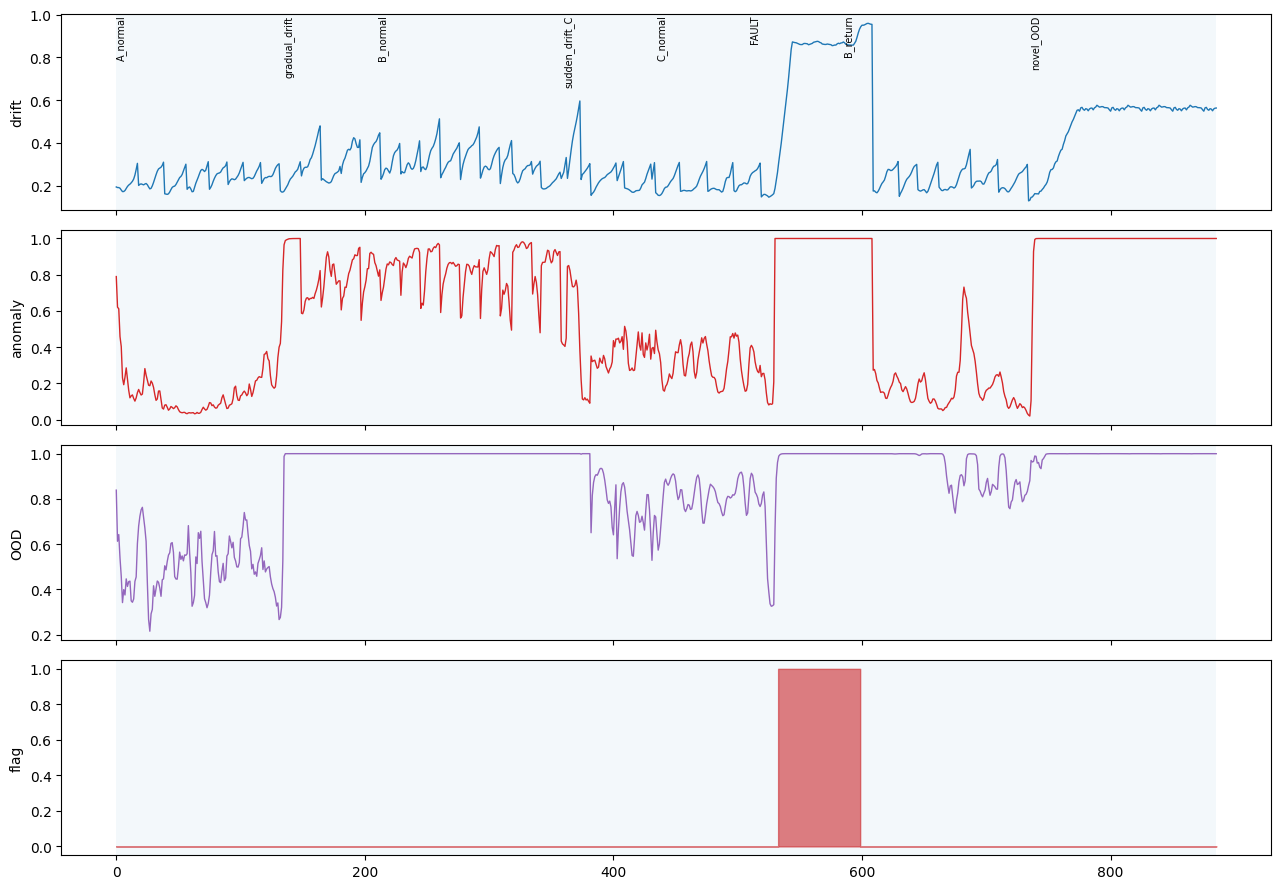

In [16]:
# 9) Visualise the decision stream
import matplotlib.pyplot as plt
import numpy as np

t = np.arange(len(records))
drift = [r["drift"] for r in records]
anom = [r["anomaly"] for r in records]
ood = [r["ood"] for r in records]
act = [1 if r["action"] in ("REJECT", "ALERT") else 0 for r in records]

fig, axs = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
axs[0].plot(t, drift, lw=1, color="tab:blue"); axs[0].set_ylabel("drift")
axs[1].plot(t, anom, lw=1, color="tab:red"); axs[1].set_ylabel("anomaly")
axs[2].plot(t, ood, lw=1, color="tab:purple"); axs[2].set_ylabel("OOD")
axs[3].fill_between(t, act, step="mid", color="tab:red", alpha=0.6)
axs[3].set_ylabel("flag")
for s in meta.segments:
    for ax in axs:
        ax.axvspan(s["win_start"], s["win_end"], alpha=0.05)
    axs[0].text(s["win_start"], 1.0, s["name"], fontsize=7, rotation=90, va="top")
plt.tight_layout()
plt.show()


In [ ]:
# 10) Save the model and download artifacts
ctrl.save("sage_model.pt")
try:
    from google.colab import files
    files.download("run_report.json")
    files.download("sage_model.pt")
except Exception as e:
    print("artifact download skipped:", e)
